# Proyecto Final de Bioinformática 2026

## Glioma Grading: clasificación LGG vs. GBM a partir de variables clínicas y 20 genes mutados

**Dataset:** *Glioma Grading Clinical and Mutation Features* (UCI ML Repository, ID 759).

**Paper cabecera:** Tasci E., Zhuge Y., Kaur H., Camphausen K., Krauze A. V. (2022). *Hierarchical Voting-Based Feature Selection and Ensemble Learning Model Scheme for Glioma Grading with Clinical and Molecular Characteristics*. Int. J. Mol. Sci., 23(22), 14155. DOI: 10.3390/ijms232214155. National Cancer Institute (NCI/NIH), EE. UU.

**Contexto biológico.** Los gliomas son tumores del sistema nervioso central que se clasifican según su grado histológico. El **LGG** (low-grade glioma, grados II-III) tiene mejor pronóstico que el **GBM** (glioblastoma, grado IV), que es el glioma más agresivo.

El dataset proviene de las cohortes **TCGA-LGG** y **TCGA-GBM** de *The Cancer Genome Atlas* y contiene, por paciente, 3 variables clínicas (`Gender`, `Age_at_diagnosis`, `Race`) y el estado de mutación (mutado / wildtype) de 20 genes que se alteran con frecuencia en glioma (entre ellos *IDH1*, *TP53*, *ATRX*, *PTEN* y *EGFR*).

**Objetivo del análisis.** Evaluamos si el perfil de mutaciones, junto con las variables clínicas, permite separar y predecir LGG vs. GBM. Para eso combinamos técnicas no supervisadas (PCA, clustering) y supervisadas (árbol de decisión, Random Forest, SVM y red neuronal), y además identificamos los genes más discriminantes.

## Sección 1: Carga e inspección inicial

**Objetivo.** Cargamos el dataset desde UCI con `ucimlrepo`, lo que evita archivos locales y garantiza la reproducibilidad en Colab. Después verificamos las dimensiones, los tipos de datos, la presencia de nulos y el balance de la variable objetivo `Grade`.

In [1]:
# ucimlrepo permite descargar el dataset directamente desde UCI (id=759)
!pip install ucimlrepo -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)

In [2]:
# Paleta consistente para todo el notebook
PALETTE_GRADE = {'LGG': '#4C72B0', 'GBM': '#DD8452'}
COLOR_LGG = '#4C72B0'
COLOR_GBM = '#DD8452'


### **Carga del dataset.**
`fetch_ucirepo(id=759)` devuelve `X` (features: 20 genes + 3 variables clínicas) e `y` (target: `Grade`). Imprimimos las dimensiones y los metadatos para confirmar que la descarga salió bien.

In [3]:
# Descargamos el dataset desde UCI (reproducible en Colab, sin archivos locales)
glioma = fetch_ucirepo(id=759)

X = glioma.data.features   # 23 features (20 genes + Gender, Age_at_diagnosis, Race)
y = glioma.data.targets    # Grade: LGG vs. GBM

print("Dimensiones de X (features):", X.shape)
print("Dimensiones de y (target):  ", y.shape)
print("\nMetadatos del dataset:")
print(glioma.metadata.name)
print("Instancias:", glioma.metadata.num_instances)
print("Features:  ", glioma.metadata.num_features)

Dimensiones de X (features): (839, 23)
Dimensiones de y (target):   (839, 1)

Metadatos del dataset:
Glioma Grading Clinical and Mutation Features
Instancias: 839
Features:   23


### **Inspección de tipos, columnas y valores nulos.**

Verificamos que no falten valores (el dataset de UCI ya viene preprocesado) y que las columnas coincidan con lo que reporta el paper: 20 genes binarios y 3 variables clínicas.

In [4]:
# Leemos los nombres reales de las columnas del dataframe, sin asumirlos
print("Columnas de X:")
print(list(X.columns))
print("\nColumnas de y:")
print(list(y.columns))

print("\nTipos de datos:")
print(X.dtypes.value_counts())

print("\nValores nulos por columna:")
print(X.isnull().sum().sum(), "valores nulos en total en X")
print(y.isnull().sum().sum(), "valores nulos en total en y")

Columnas de X:
['Gender', 'Age_at_diagnosis', 'Race', 'IDH1', 'TP53', 'ATRX', 'PTEN', 'EGFR', 'CIC', 'MUC16', 'PIK3CA', 'NF1', 'PIK3R1', 'FUBP1', 'RB1', 'NOTCH1', 'BCOR', 'CSMD3', 'SMARCA4', 'GRIN2A', 'IDH2', 'FAT4', 'PDGFRA']

Columnas de y:
['Grade']

Tipos de datos:
int64      21
float64     1
object      1
Name: count, dtype: int64

Valores nulos por columna:
0 valores nulos en total en X
0 valores nulos en total en y


### **Primeras filas y estadísticas descriptivas.**

Confirmamos la codificación real de las variables (0/1 en los genes, valores continuos en la edad) y revisamos el rango de `Age_at_diagnosis`.

In [5]:
print("Primeras 5 filas de X:")
display(X.head())

Primeras 5 filas de X:


,Gender,Age_at_diagnosis,Race,IDH1,TP53,ATRX,PTEN,EGFR,CIC,MUC16,PIK3CA,NF1,PIK3R1,FUBP1,RB1,NOTCH1,BCOR,CSMD3,SMARCA4,GRIN2A,IDH2,FAT4,PDGFRA
0,0,51.30,white,1,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0
1,0,38.72,white,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,35.17,white,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,1,32.78,white,1,1,1,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,1,0
4,0,31.51,white,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [6]:
print("Primeras 5 filas de y:")
display(y.head())

Primeras 5 filas de y:


,Grade
0,0
1,0
2,0
3,0
4,0


In [7]:
print("Estadísticas descriptivas de X (numéricas):")
display(X.describe().T)

Estadísticas descriptivas de X (numéricas):


,count,mean,std,min,25%,50%,75%,max
Gender,839.0,0.418355,0.493583,0.00,0.000,0.00,1.0,1.00
Age_at_diagnosis,839.0,50.935411,15.702339,14.42,38.055,51.55,62.8,89.29
IDH1,839.0,0.481526,0.499957,0.00,0.000,0.00,1.0,1.00
TP53,839.0,0.414779,0.492978,0.00,0.000,0.00,1.0,1.00
ATRX,839.0,0.258641,0.438149,0.00,0.000,0.00,1.0,1.00
PTEN,839.0,0.168057,0.374140,0.00,0.000,0.00,0.0,1.00
EGFR,839.0,0.133492,0.340309,0.00,0.000,0.00,0.0,1.00
CIC,839.0,0.132300,0.339019,0.00,0.000,0.00,0.0,1.00
MUC16,839.0,0.116806,0.321380,0.00,0.000,0.00,0.0,1.00
PIK3CA,839.0,0.087008,0.282015,0.00,0.000,0.00,0.0,1.00


### **Balance de la variable objetivo.**

Contamos cuántos pacientes hay en cada grado. Este dato es clave: si las clases están desbalanceadas, la accuracy sola puede engañar y conviene mirar también precision, recall y F1 por clase.

In [8]:
print("Distribución de Grade:")
print(y['Grade'].value_counts())

Distribución de Grade:
Grade
0    487
1    352
Name: count, dtype: int64


In [9]:
print("Proporción (%):")
print((y['Grade'].value_counts(normalize=True) * 100).round(2))

Proporción (%):
Grade
0    58.05
1    41.95
Name: proportion, dtype: float64


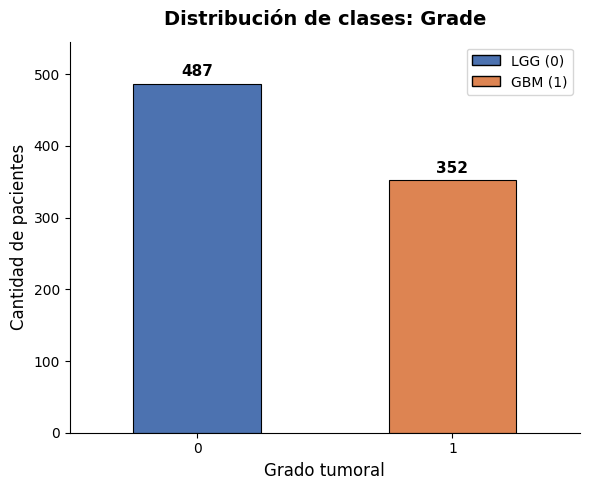

In [10]:
# Gráfico de barras con la distribución de clases
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(6, 5))
conteo_clases = y['Grade'].value_counts()
colores_clases = [COLOR_LGG if g == 0 else COLOR_GBM for g in conteo_clases.index]  # Grade: 0 = LGG, 1 = GBM
conteo_clases.plot(kind='bar', color=colores_clases, edgecolor='black', linewidth=0.8, ax=ax)

# Conteo encima de cada barra
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2, p.get_height()),
                xytext=(0, 3), textcoords='offset points',
                fontsize=11, fontweight='bold', ha='center', va='bottom')

ax.set_title('Distribución de clases: Grade', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Grado tumoral', fontsize=12)
ax.set_ylabel('Cantidad de pacientes', fontsize=12)
ax.tick_params(axis='x', labelrotation=0)
ax.margins(y=0.12)  # margen superior para que entren las anotaciones
ax.legend(handles=[Patch(facecolor=COLOR_LGG, edgecolor='black', label='LGG (0)'),
                   Patch(facecolor=COLOR_GBM, edgecolor='black', label='GBM (1)')],
          frameon=True, fontsize=10, loc='best')
sns.despine(ax=ax)
plt.tight_layout()
# plt.savefig('fig_01_distribucion_clases.png', dpi=300, bbox_inches='tight')
plt.show()


### Conclusión parcial 1: Calidad del dataset

**Tamaño y estructura.** El dataset tiene 839 pacientes × 23 features (20 genes + 3 clínicas) más el target `Grade`. No hay valores nulos en X ni en y. La única columna de tipo `object` es `Race` (texto), que hay que codificar.

**Codificación confirmada (metadatos UCI).**
- `Grade`: 0 = LGG (487 pacientes, 58.05 %), 1 = GBM (352 pacientes, 41.95 %). El desbalance es moderado (ratio ≈ 1.4:1).
- `Gender`: 0 = male, 1 = female (41.8 % female).
- `Age_at_diagnosis`: continua, de 14.42 a 89.29 años, con media 50.94 ± 15.70.
- `Race`: categórica nominal (texto). La codificamos con one-hot (`pd.get_dummies`, `drop_first=True`) para no introducir una ordinalidad falsa.
- **20 genes**: binarios 0/1 (NOT_MUTATED / MUTATED). La frecuencia global es muy heterogénea: *IDH1* (≈48 %), *TP53* (≈41 %) y *ATRX* (≈26 %) son los más mutados, mientras que *PIK3CA* a *PDGFRA* (entre ≈2 y 9 %) son los menos mutados.

**Implicancias.** (a) El desbalance moderado exige usar `stratify=y` y reportar precision, recall y F1 además de la accuracy. (b) Los genes con frecuencia menor al 5 % pueden aportar poco de forma individual, pero sí en conjunto. (c) `Race` tiene que codificarse antes de modelar.

### **Verificación de la codificación de `Grade`.**

El target viene como entero 0/1, no como texto. Antes de interpretarlo, leemos el metadato oficial de las variables que entrega `ucimlrepo` (campos `description` y `value` de cada variable). Así evitamos rotular mal LGG y GBM.

In [11]:
# Metadatos de variables: incluye descripción de codificación (útil para Grade y Gender)
display(glioma.variables)

,name,role,type,demographic,description,units,missing_values
0,Grade,Target,Categorical,None,"Glioma grade class information (0 = ""LGG""; 1 =...",N/A,no
1,Gender,Feature,Categorical,Gender,"Gender (0 = ""male""; 1 = ""female"")",N/A,no
2,Age_at_diagnosis,Feature,Continuous,Age,Age at diagnosis with the calculated number of...,years,no
3,Race,Feature,Categorical,Race,"Race (0 = ""white""; 1 = ""black or african Ame...",N/A,no
4,IDH1,Feature,Categorical,None,isocitrate dehydrogenase (NADP(+))1 (0 = NOT_M...,N/A,no
5,TP53,Feature,Categorical,None,tumor protein p53 (0 = NOT_MUTATED; 1 = MUTATED),N/A,no
6,ATRX,Feature,Categorical,None,ATRX chromatin remodeler (0 = NOT_MUTATED; 1 =...,N/A,no
7,PTEN,Feature,Categorical,None,phosphatase and tensin homolog (0 = NOT_MUTATE...,N/A,no
8,EGFR,Feature,Categorical,None,epidermal growth factor receptor (0 = NOT_MUTA...,N/A,no
9,CIC,Feature,Categorical,None,capicua transcriptional repressor (0 = NOT_MUT...,N/A,no


## Sección 2: Preprocesamiento y análisis exploratorio

**Objetivo.**
1. Codificar `Grade` a una etiqueta legible (LGG/GBM) y `Race` a formato numérico, sin fuga de datos.
2. Explorar visualmente qué variables clínicas y qué genes separan mejor LGG de GBM: la edad por grado, la frecuencia de mutación de los 20 genes comparada entre clases y las correlaciones entre variables.
3. Dejar `X` numérico y listo para PCA y clustering (el escalado se hace al final de la sección).

### **Codificación del target y de `Race`.**

`Grade` ya viene como 0/1, así que creamos una columna de texto `Grade_label` (LGG/GBM) solo para visualización.

`Race` se convierte a dummies (one-hot, `drop_first=True`) para evitar una ordinalidad falsa.

Armamos un único DataFrame `df` con las features y el target.

In [12]:
# Unimos X e y en un solo DataFrame para el EDA
df = X.copy()
df['Grade'] = y['Grade'].values                       # 0=LGG, 1=GBM (numérico, para los modelos)
df['Grade_label'] = df['Grade'].map({0: 'LGG', 1: 'GBM'})  # texto, solo para los gráficos

In [13]:
# Codificamos Race (nominal) con one-hot; drop_first evita la colinealidad perfecta
print("Categorías de Race:")
print(df['Race'].value_counts())
df = pd.get_dummies(df, columns=['Race'], drop_first=True, dtype=int)

Categorías de Race:
Race
white                               765
black or african american            59
asian                                14
american indian or alaska native      1
Name: count, dtype: int64


In [14]:
print("\nColumnas tras codificar Race:")
print(list(df.columns))


Columnas tras codificar Race:
['Gender', 'Age_at_diagnosis', 'IDH1', 'TP53', 'ATRX', 'PTEN', 'EGFR', 'CIC', 'MUC16', 'PIK3CA', 'NF1', 'PIK3R1', 'FUBP1', 'RB1', 'NOTCH1', 'BCOR', 'CSMD3', 'SMARCA4', 'GRIN2A', 'IDH2', 'FAT4', 'PDGFRA', 'Grade', 'Grade_label', 'Race_asian', 'Race_black or african american', 'Race_white']


In [15]:
print("\nPrimeras filas:")
display(df.head())


Primeras filas:


,Gender,Age_at_diagnosis,IDH1,TP53,ATRX,PTEN,EGFR,CIC,MUC16,PIK3CA,NF1,PIK3R1,FUBP1,RB1,NOTCH1,BCOR,CSMD3,SMARCA4,GRIN2A,IDH2,FAT4,PDGFRA,Grade,Grade_label,Race_asian,Race_black or african american,Race_white
0,0,51.30,1,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,LGG,0,0,1
1,0,38.72,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,LGG,0,0,1
2,0,35.17,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,LGG,0,0,1
3,1,32.78,1,1,1,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,1,0,0,LGG,0,0,1
4,0,31.51,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,LGG,0,0,1


### **Edad por grado tumoral.**

Hacemos un boxplot de `Age_at_diagnosis` separado por LGG y GBM. Los gliomas de mayor grado suelen aparecer en edades más avanzadas, y acá verificamos si ese patrón se observa en esta cohorte.

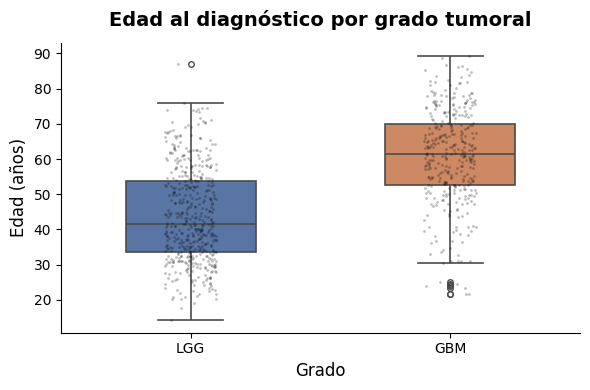

In [16]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(data=df, x='Grade_label', y='Age_at_diagnosis', hue='Grade_label',
            palette=PALETTE_GRADE, width=0.5, linewidth=1.2, fliersize=4, legend=False, ax=ax)
sns.stripplot(data=df, x='Grade_label', y='Age_at_diagnosis',
              color='black', alpha=0.25, size=2, jitter=True, ax=ax)
ax.set_title('Edad al diagnóstico por grado tumoral', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Grado', fontsize=12)
ax.set_ylabel('Edad (años)', fontsize=12)
sns.despine(ax=ax)
plt.tight_layout()
# plt.savefig('fig_02_edad_por_grado.png', dpi=300, bbox_inches='tight')
plt.show()


In [17]:
# Resumen numérico que usamos en la conclusión
print(df.groupby('Grade_label')['Age_at_diagnosis'].describe()[['mean','std','min','50%','max']])

                  mean        std    min     50%    max
Grade_label                                            
GBM          60.703750  13.427080  21.73  61.395  89.29
LGG          43.874928  13.261726  14.42  41.610  87.00


###**Frecuencia de mutación por gen y grado.**

Para cada uno de los 20 genes calculamos la proporción de pacientes mutados en LGG y en GBM, y ordenamos por la diferencia absoluta entre clases. Los genes con mayor diferencia son los candidatos más discriminantes.

In [18]:
genes = [c for c in X.columns if c not in ['Gender', 'Age_at_diagnosis', 'Race']]

In [19]:
# Proporción de pacientes mutados por gen y grado
mut_por_grado = df.groupby('Grade_label')[genes].mean().T   # filas = genes, columnas = LGG/GBM
mut_por_grado['diff_abs'] = (mut_por_grado['GBM'] - mut_por_grado['LGG']).abs()
mut_por_grado = mut_por_grado.sort_values('diff_abs', ascending=False)

print("Proporción de mutación por gen y grado (ordenado por |GBM − LGG|):")
display((mut_por_grado * 100).round(2))

Proporción de mutación por gen y grado (ordenado por |GBM − LGG|):


Grade_label,GBM,LGG,diff_abs
IDH1,6.53,78.23,71.70
ATRX,9.66,37.58,27.92
PTEN,32.95,5.13,27.82
CIC,1.14,21.97,20.83
EGFR,23.01,6.37,16.65
TP53,32.10,48.25,16.15
RB1,9.66,1.23,8.43
FUBP1,0.57,8.83,8.26
NOTCH1,0.00,7.80,7.80
MUC16,16.19,8.42,7.77


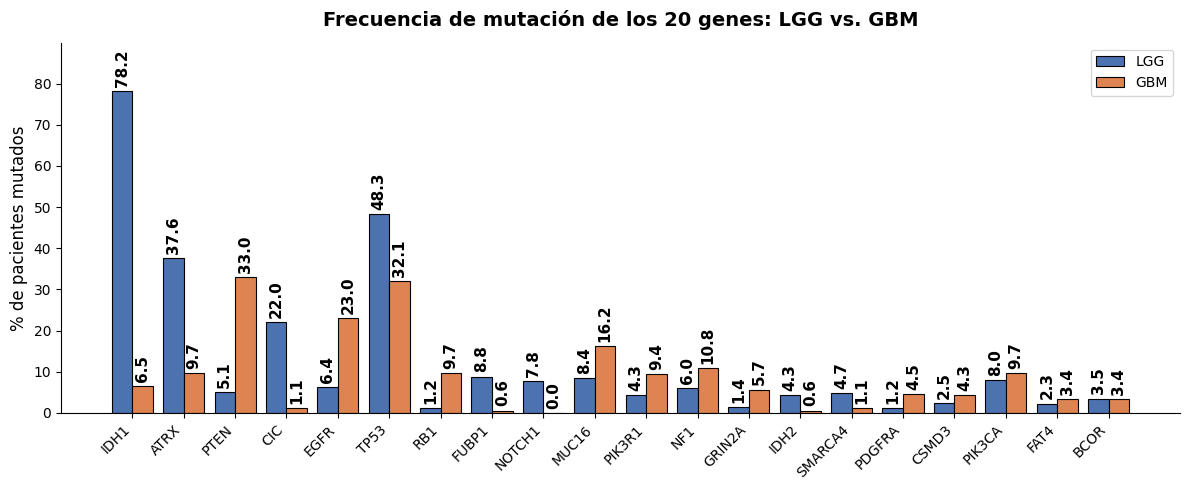

In [20]:
# Barplot agrupado por gen
fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(mut_por_grado))
w = 0.4
ax.bar(x - w/2, mut_por_grado['LGG'] * 100, w, label='LGG', color=COLOR_LGG, edgecolor='black', linewidth=0.8)
ax.bar(x + w/2, mut_por_grado['GBM'] * 100, w, label='GBM', color=COLOR_GBM, edgecolor='black', linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(mut_por_grado.index, rotation=45, ha='right')

# Valor (%) encima de cada barra
for p in ax.patches:
    ax.annotate(f'{p.get_height():.1f}', (p.get_x() + p.get_width() / 2, p.get_height()),
                xytext=(0, 3), textcoords='offset points', rotation=90,
                fontsize=11, fontweight='bold', ha='center', va='bottom')

ax.set_ylabel('% de pacientes mutados', fontsize=12)
ax.set_title('Frecuencia de mutación de los 20 genes: LGG vs. GBM', fontsize=14, fontweight='bold', pad=12)
ax.margins(y=0.15)  # margen superior para que entren las anotaciones
ax.legend(frameon=True, fontsize=10, loc='best')
sns.despine(ax=ax)
plt.tight_layout()
# plt.savefig('fig_03_frecuencia_mutacion_genes.png', dpi=300, bbox_inches='tight')
plt.show()


### **Mapa de correlaciones.**

Armamos un heatmap de correlación entre los genes, la edad, el género y el target numérico (`Grade`). Nos sirve para detectar genes que se mutan juntos (co-ocurrencia) y para ver cuáles correlacionan más con el grado.

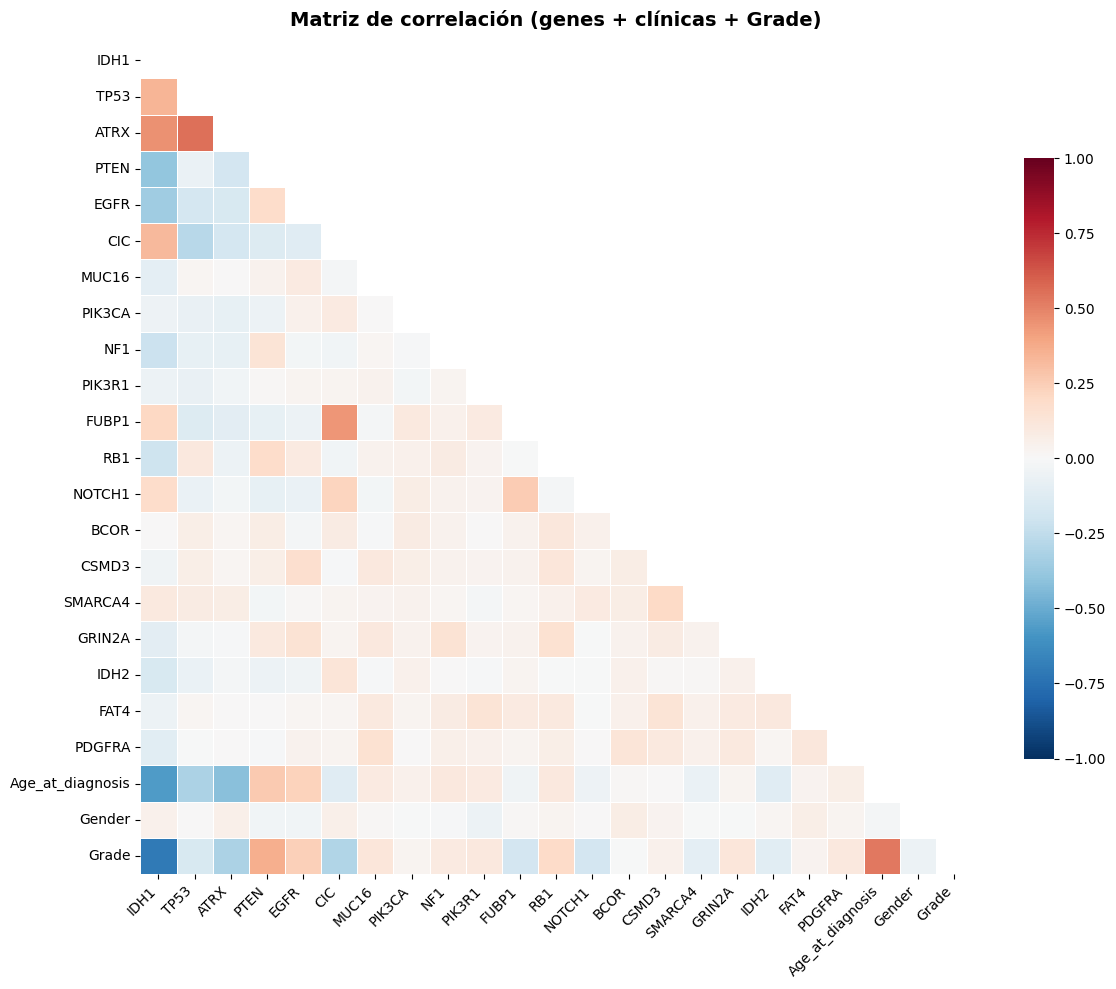

In [21]:
# Correlación entre genes, variables clínicas numéricas y Grade
cols_corr = genes + ['Age_at_diagnosis', 'Gender', 'Grade']
corr = df[cols_corr].corr()

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            mask=np.triu(np.ones_like(corr, dtype=bool)),
            square=True, linewidths=0.5, linecolor='white',
            cbar_kws={'shrink': 0.7}, ax=ax)
ax.set_title('Matriz de correlación (genes + clínicas + Grade)', fontsize=14, fontweight='bold', pad=12)
plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
plt.tight_layout()
# plt.savefig('fig_04_matriz_correlacion.png', dpi=300, bbox_inches='tight')
plt.show()


In [22]:
# Correlaciones más fuertes con Grade (excluimos la de Grade consigo misma)
corr_grade = corr['Grade'].drop('Grade').sort_values(key=abs, ascending=False)
print("Correlación de cada variable con Grade (ordenado por |r|):")
print(corr_grade.round(3))

Correlación de cada variable con Grade (ordenado por |r|):
IDH1               -0.708
Age_at_diagnosis    0.529
PTEN                0.367
ATRX               -0.315
CIC                -0.303
EGFR                0.242
RB1                 0.195
NOTCH1             -0.185
FUBP1              -0.181
TP53               -0.162
MUC16               0.119
GRIN2A              0.119
IDH2               -0.113
PDGFRA              0.102
PIK3R1              0.102
SMARCA4            -0.100
NF1                 0.088
Gender             -0.060
CSMD3               0.050
FAT4                0.035
PIK3CA              0.029
BCOR               -0.002
Name: Grade, dtype: float64


### **Escalado para PCA y clustering.**

`MinMaxScaler` lleva cada variable al rango [0, 1]. En los métodos **no supervisados** (PCA, K-Means, jerárquico) no hay fuga de etiquetas, así que ajustamos el escalado sobre todo el dataset.

En los modelos **supervisados** (Sección 5) el escalado se ajustará solo en `train`.

Guardamos `X_norm` para la Sección 3.

In [23]:
from sklearn.preprocessing import MinMaxScaler

# X numérico final (sin Grade ni Grade_label)
X_num = df.drop(columns=['Grade', 'Grade_label']).values
feature_names = df.drop(columns=['Grade', 'Grade_label']).columns.tolist()

scaler = MinMaxScaler()
X_norm = scaler.fit_transform(X_num)

print("X_num:", X_num.shape, "| X_norm:", X_norm.shape)
print("Rango de X_norm: min =", X_norm.min().round(2), "| max =", X_norm.max().round(2))

X_num: (839, 25) | X_norm: (839, 25)
Rango de X_norm: min = 0.0 | max = 1.0


### Conclusión parcial 2: Variables con mayor separación preliminar

**Edad.** Los GBM son unos 17 años mayores que los LGG al momento del diagnóstico (media 60.70 vs. 43.87 años; medianas 61.39 vs. 41.61). La edad por sí sola ya da una señal fuerte (r = +0.53 con `Grade`), algo consistente con la epidemiología conocida del glioblastoma, que es más frecuente en adultos mayores.

**Genes más discriminantes (por |GBM − LGG| en proporción de mutación):**

| Gen | % LGG | % GBM | Dirección |
|---|---|---|---|
| **IDH1** | 78.23 | 6.53 | LGG (r = −0.708) |
| **ATRX** | 37.58 | 9.66 | LGG (r = −0.315) |
| **PTEN** | 5.13 | 32.95 | GBM (r = +0.367) |
| **CIC**  | 21.97 | 1.14 | LGG (r = −0.303) |
| **EGFR** | 6.37  | 23.01 | GBM (r = +0.242) |
| **TP53** | 48.25 | 32.10 | leve LGG (r = −0.162) |

**Observaciones clave.**
- `IDH1` es, por lejos, el gen más informativo: el 78 % de los LGG lo tiene mutado, contra solo el 6.5 % de los GBM. En esta cohorte funciona como el marcador molecular central del glioma de bajo grado.
- Patrón enriquecido en LGG: `IDH1`, `ATRX`, `CIC`, `NOTCH1`, `FUBP1`, `IDH2` y `SMARCA4`.
- Patrón enriquecido en GBM: `PTEN`, `EGFR`, `RB1`, `MUC16`, `GRIN2A` y `PDGFRA`.
- `TP53` está mutado con frecuencia alta en ambas clases (48 % vs. 32 %), por lo que aporta poco como discriminante individual, aunque puede sumar en combinación con otras variables.
- `BCOR` es prácticamente neutro (3.49 % en LGG vs. 3.41 % en GBM, r ≈ 0), y `PIK3CA`, `FAT4` y `CSMD3` casi no aportan.

**Correlación con Grade (top por |r|):** `IDH1` (−0.71), `Age_at_diagnosis` (+0.53), `PTEN` (+0.37), `ATRX` (−0.32), `CIC` (−0.30) y `EGFR` (+0.24). Estas seis variables concentran casi toda la señal lineal del dataset.

**Implicancia para el modelado.** Tres features (IDH1, edad y PTEN) ya capturan la mayor parte de la separación lineal. Esperamos que los modelos de la Sección 5 alcancen un buen desempeño con pocos predictores, y que el clustering de la Sección 4 separe bien los grupos, con IDH1 dominando la primera componente principal.

**Nota metodológica.** La categoría de referencia de los dummies de `Race` es *"american indian or alaska native"* (n = 1). Es una elección válida, pero la base de comparación queda casi vacía, y conviene tenerlo presente al interpretar los coeficientes de `Race_*` en modelos lineales.

## Sección 3: Reducción de dimensionalidad (PCA)

**Objetivo.** Proyectamos los 25 features escalados en un espacio de menor dimensión para:
1. visualizar si LGG y GBM se separan en 2D,
2. identificar qué genes dominan las componentes principales (loadings),
3. usar las componentes como entrada del clustering en la Sección 4.

**Advertencia de fuga de datos.** Para PCA y K-Means (no supervisados, sin etiquetas) ajustamos el scaler sobre **todo el dataset** (`X_norm`), que ya preparamos en la Sección 2. En la Sección 5, cuando entrenemos los modelos supervisados, el escalado se ajustará **solo sobre train**.

### **Ajuste de PCA y varianza explicada.**

Ajustamos `PCA()` con todos los componentes sobre `X_norm`, armamos la tabla resumen (desvío estándar, proporción y proporción acumulada) y graficamos el **scree plot** para decidir cuántas componentes conservar.

In [24]:
from sklearn.decomposition import PCA

pca = PCA(random_state=42)
X_pca = pca.fit_transform(X_norm)

# Tabla resumen de la varianza explicada
pca_df = pd.DataFrame({
    'std': np.sqrt(pca.explained_variance_),
    'var_ratio': pca.explained_variance_ratio_,
    'cum_var': np.cumsum(pca.explained_variance_ratio_)
}, index=[f'PC{i}' for i in range(1, len(pca.explained_variance_) + 1)])

print("Resumen PCA (primeras 10 componentes):")
display(pca_df.head(10).round(4))

print("\nVarianza explicada acumulada en PC1+PC2:", round(pca_df['cum_var'].iloc[1]*100, 2), "%")
print("Componentes para ≥ 90 % de varianza:", int(np.argmax(pca_df['cum_var'].values >= 0.90) + 1))
print("Componentes para ≥ 95 % de varianza:", int(np.argmax(pca_df['cum_var'].values >= 0.95) + 1))

Resumen PCA (primeras 10 componentes):


,std,var_ratio,cum_var
PC1,0.6954,0.2231,0.2231
PC2,0.5168,0.1232,0.3463
PC3,0.4907,0.1111,0.4573
PC4,0.3734,0.0643,0.5216
PC5,0.3389,0.0530,0.5746
PC6,0.3335,0.0513,0.6259
PC7,0.3142,0.0455,0.6715
PC8,0.3051,0.0429,0.7144
PC9,0.2877,0.0382,0.7526
PC10,0.2666,0.0328,0.7854



Varianza explicada acumulada en PC1+PC2: 34.63 %
Componentes para ≥ 90 % de varianza: 16
Componentes para ≥ 95 % de varianza: 20


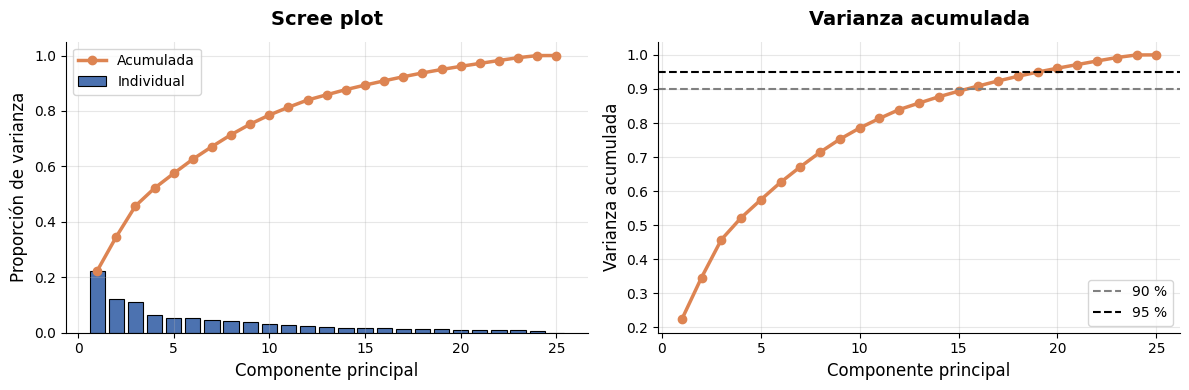

In [25]:
# Scree plot y varianza acumulada
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
pcs = np.arange(1, len(pca_df) + 1)
axes[0].bar(pcs, pca_df['var_ratio'], color=COLOR_LGG, edgecolor='black', linewidth=0.8, label='Individual')
axes[0].plot(pcs, pca_df['cum_var'], '-o', color=COLOR_GBM, lw=2.5, markersize=6, label='Acumulada')
axes[0].set_xlabel('Componente principal', fontsize=12)
axes[0].set_ylabel('Proporción de varianza', fontsize=12)
axes[0].set_title('Scree plot', fontsize=14, fontweight='bold', pad=12)
axes[0].legend(frameon=True, fontsize=10, loc='best')
axes[0].grid(alpha=0.3)
sns.despine(ax=axes[0])

axes[1].plot(pcs, pca_df['cum_var'], '-o', color=COLOR_GBM, lw=2.5, markersize=6)
axes[1].axhline(0.90, color='gray', ls='--', lw=1.5, label='90 %')
axes[1].axhline(0.95, color='black', ls='--', lw=1.5, label='95 %')
axes[1].set_xlabel('Componente principal', fontsize=12)
axes[1].set_ylabel('Varianza acumulada', fontsize=12)
axes[1].set_title('Varianza acumulada', fontsize=14, fontweight='bold', pad=12)
axes[1].legend(frameon=True, fontsize=10, loc='best')
axes[1].grid(alpha=0.3)
sns.despine(ax=axes[1])
plt.tight_layout()
# plt.savefig('fig_05_scree_plot.png', dpi=300, bbox_inches='tight')
plt.show()


### **Scatter PC1 vs. PC2 coloreado por grado.**

Si LGG y GBM se separan en el plano PC1-PC2, la clasificación supervisada debería funcionar bien. Si se solapan, vamos a necesitar más componentes o modelos no lineales.

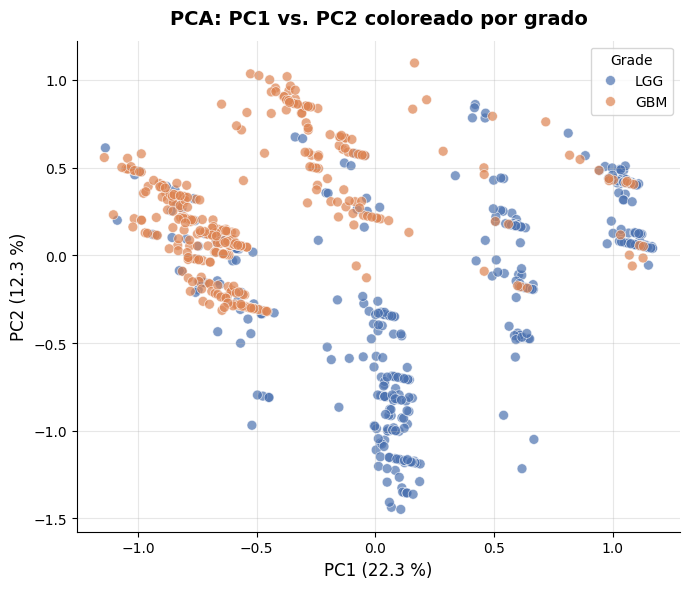

In [26]:
fig, ax = plt.subplots(figsize=(7, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=df['Grade_label'].values,
                hue_order=['LGG', 'GBM'], palette=PALETTE_GRADE,
                s=50, alpha=0.7, edgecolor='white', linewidth=0.5, ax=ax)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f} %)", fontsize=12)
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f} %)", fontsize=12)
ax.set_title('PCA: PC1 vs. PC2 coloreado por grado', fontsize=14, fontweight='bold', pad=12)
ax.legend(title='Grade', frameon=True, fontsize=10, loc='best')
ax.grid(alpha=0.3)
sns.despine(ax=ax)
plt.tight_layout()
# plt.savefig('fig_06_pca_pc1_pc2.png', dpi=300, bbox_inches='tight')
plt.show()


### **Loadings (pesos de cada variable en PC1 y PC2).**

Los genes con mayor |loading| en PC1 son los que más contribuyen a la dirección de máxima varianza. En este dataset esperamos que `IDH1` domine PC1.

In [27]:
loadings = pca.components_.T
loadings_df = pd.DataFrame(loadings[:, :3],
                           columns=['PC1', 'PC2', 'PC3'],
                           index=feature_names)

print("Top 10 variables con mayor |loading| en PC1:")
print(loadings_df['PC1'].abs().sort_values(ascending=False).head(10).round(3))
print("\nTop 10 variables con mayor |loading| en PC2:")
print(loadings_df['PC2'].abs().sort_values(ascending=False).head(10).round(3))

Top 10 variables con mayor |loading| en PC1:
IDH1                              0.598
TP53                              0.512
ATRX                              0.483
PTEN                              0.223
EGFR                              0.199
Age_at_diagnosis                  0.183
NF1                               0.078
Gender                            0.067
Race_white                        0.057
Race_black or african american    0.052
Name: PC1, dtype: float64

Top 10 variables con mayor |loading| en PC2:
TP53      0.518
CIC       0.472
IDH1      0.389
Gender    0.361
PTEN      0.276
ATRX      0.240
FUBP1     0.184
EGFR      0.146
NOTCH1    0.108
RB1       0.087
Name: PC2, dtype: float64


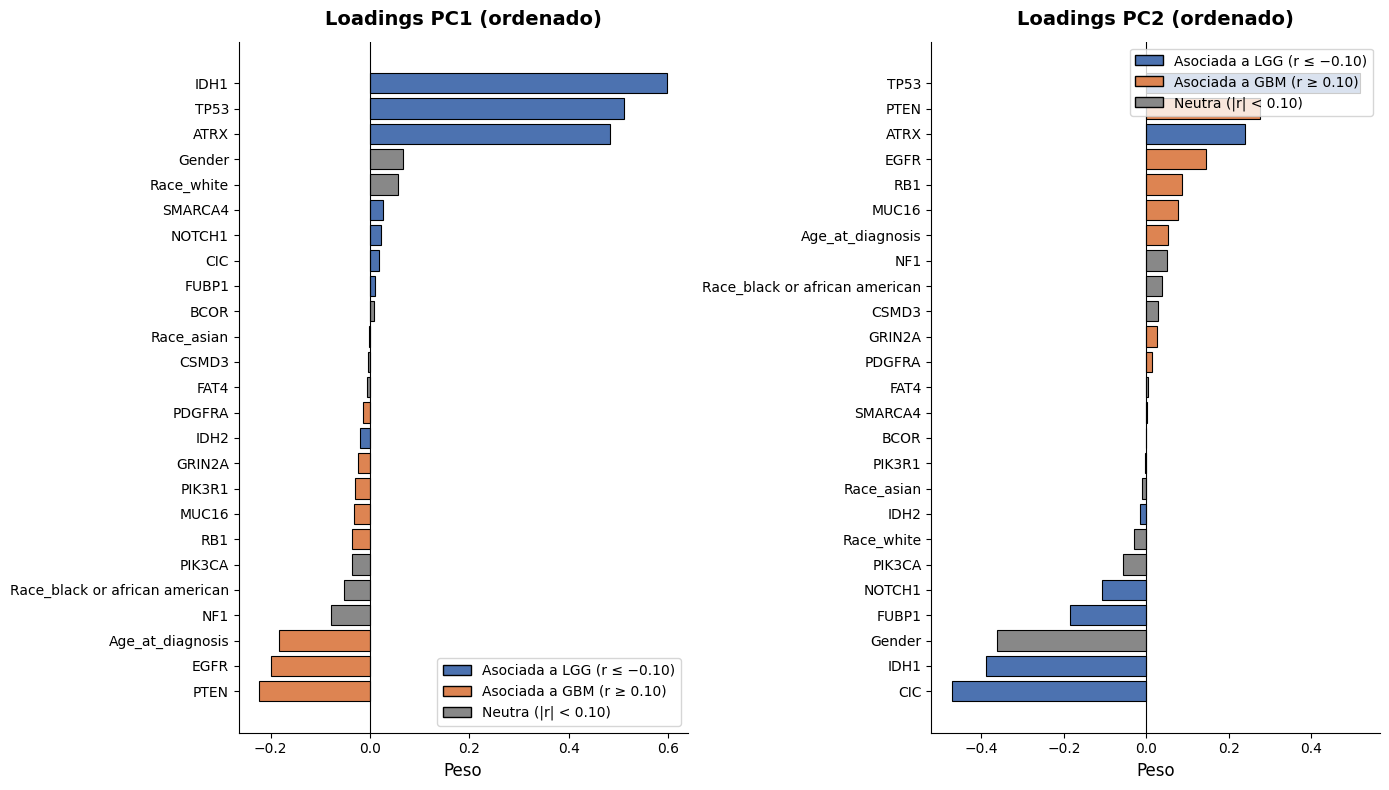

In [28]:
# Barplot de los loadings de PC1 y PC2, ordenados por valor
from matplotlib.patches import Patch

# Color coherente con el resto del notebook, según la correlación de cada variable con Grade
# (corr_grade, calculada antes): azul = marcador de LGG, naranja = marcador de GBM, gris = neutro
def _color_loading(var, umbral=0.10):
    r = corr_grade.get(var, 0.0)
    if r >= umbral:
        return COLOR_GBM
    if r <= -umbral:
        return COLOR_LGG
    return '#888888'

handles_loadings = [Patch(facecolor=COLOR_LGG, edgecolor='black', label='Asociada a LGG (r ≤ −0.10)'),
                    Patch(facecolor=COLOR_GBM, edgecolor='black', label='Asociada a GBM (r ≥ 0.10)'),
                    Patch(facecolor='#888888', edgecolor='black', label='Neutra (|r| < 0.10)')]

fig, axes = plt.subplots(1, 2, figsize=(14, 8))
pc1 = loadings_df['PC1'].sort_values()
axes[0].barh(pc1.index, pc1.values, color=[_color_loading(v) for v in pc1.index],
             edgecolor='black', linewidth=0.8)
axes[0].set_title('Loadings PC1 (ordenado)', fontsize=14, fontweight='bold', pad=12)
axes[0].set_xlabel('Peso', fontsize=12)
axes[0].axvline(0, color='black', lw=0.8)
axes[0].legend(handles=handles_loadings, frameon=True, fontsize=10, loc='best')

pc2 = loadings_df['PC2'].sort_values()
axes[1].barh(pc2.index, pc2.values, color=[_color_loading(v) for v in pc2.index],
             edgecolor='black', linewidth=0.8)
axes[1].set_title('Loadings PC2 (ordenado)', fontsize=14, fontweight='bold', pad=12)
axes[1].set_xlabel('Peso', fontsize=12)
axes[1].axvline(0, color='black', lw=0.8)
axes[1].legend(handles=handles_loadings, frameon=True, fontsize=10, loc='best')

for a in axes:
    a.tick_params(axis='y', labelsize=10)
    sns.despine(ax=a)
plt.tight_layout()
# plt.savefig('fig_07_loadings_pca.png', dpi=300, bbox_inches='tight')
plt.show()


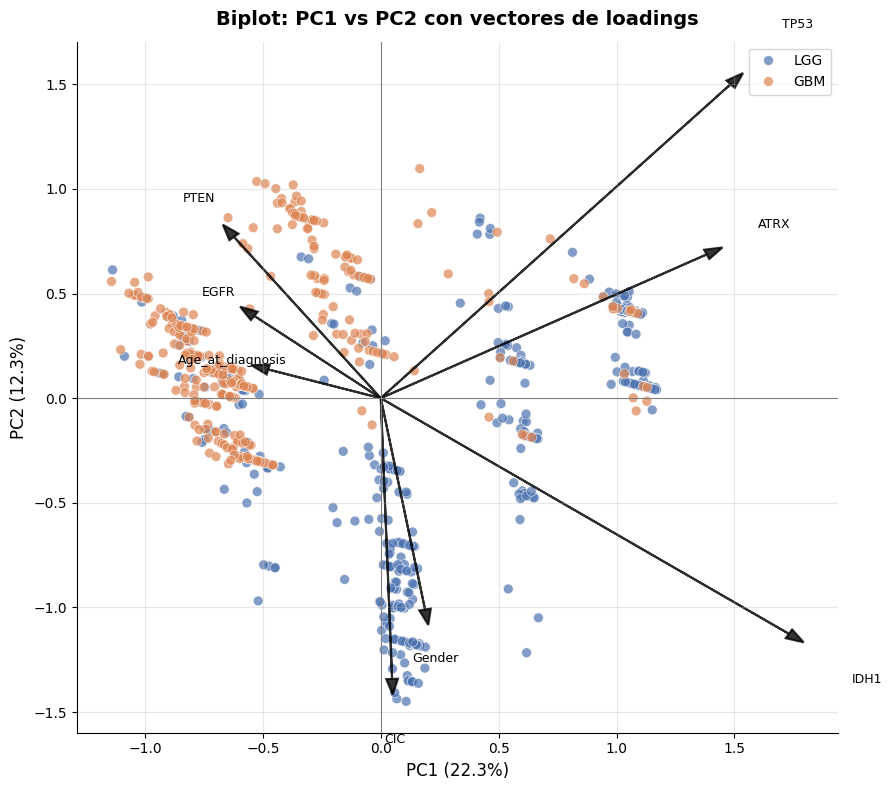

In [29]:
# Biplot: muestras + vectores de loadings
# Combina el scatter de pacientes con flechas que representan
# la dirección de los genes en el plano PC1-PC2.

fig, ax = plt.subplots(figsize=(9, 8))

# Scatter de muestras
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=df['Grade_label'].values,
                hue_order=['LGG', 'GBM'], palette=PALETTE_GRADE,
                s=50, alpha=0.7, edgecolor='white', linewidth=0.5, ax=ax)

# Vectores de loadings (top 8 por magnitud en el plano PC1-PC2)
top_n = 8
magnitud = np.sqrt(loadings[:, 0]**2 + loadings[:, 1]**2)
top_idx = np.argsort(magnitud)[::-1][:top_n]

escala = 3.0  # ajustar visualmente si las flechas quedan muy largas o cortas
for i in top_idx:
    lx, ly = loadings[i, 0], loadings[i, 1]
    ax.arrow(0, 0, lx*escala, ly*escala,
             color='black', alpha=0.8, head_width=0.05, linewidth=1.5,
             length_includes_head=True)
    ax.text(lx*escala*1.15, ly*escala*1.15, feature_names[i],
            color='black', ha='center', va='center', fontsize=9)

ax.axhline(0, color='gray', lw=0.8)
ax.axvline(0, color='gray', lw=0.8)
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)', fontsize=12)
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)', fontsize=12)
ax.set_title('Biplot: PC1 vs PC2 con vectores de loadings', fontsize=14, fontweight='bold', pad=12)
ax.legend(frameon=True, fontsize=10, loc='best')
ax.grid(alpha=0.3)
sns.despine(ax=ax)
plt.tight_layout()
# plt.savefig('fig_08_biplot_pca.png', dpi=300, bbox_inches='tight')
plt.show()


### Conclusión parcial 3: Separación en el espacio PCA

**Varianza explicada.** PC1 = 22.3 % y PC2 = 12.3 % (acumulado 34.6 %). Para retener el 90 % de la varianza hacen falta **16 componentes**, y para el 95 %, **20**. La información está muy distribuida y no hay una dirección claramente dominante, algo consistente con un dataset mayoritariamente binario (mutaciones).

**¿Se separan LGG y GBM en 2D?** **No de forma lineal.** El scatter PC1-PC2 muestra un solapamiento extenso, aunque hay estructura: los GBM tienden a concentrarse en el cuadrante PC1<0 / PC2>0, y los LGG se dispersan en abanico, con una "cola" vertical cerca de PC1≈0. La separación va a requerir modelos supervisados en el espacio completo (23D), y no alcanza con una frontera lineal en 2 componentes.

**Loadings (genes dominantes).**
- **PC1:** IDH1 (+0.60), TP53 (+0.51), ATRX (+0.48), PTEN (+0.22), EGFR (+0.20) y Age (+0.18). El eje de máxima varianza está dominado por los genes clásicos del glioma.
- **PC2:** TP53 (+0.52), CIC (+0.47), IDH1 (+0.39), Gender (+0.36), PTEN (+0.28) y ATRX (+0.24). PC2 mezcla TP53 y CIC con género y PTEN, y probablemente captura un eje clínico-molecular secundario.

**Interpretación.** IDH1, TP53 y ATRX (los tres con mayor |loading| en PC1) coinciden con los genes que en la Sección 2 mostraron mayor correlación con `Grade` (IDH1 r = −0.71, ATRX r = −0.32). TP53 es un caso particular: tiene alta frecuencia en ambas clases, pero su aporte cambia según la combinación con otras variables. PC1 parece capturar el eje **LGG (IDH1+/ATRX+) vs. GBM (IDH1−/PTEN+/EGFR+)**.

**Para la Sección 4.** Vamos a correr K-Means y el clustering jerárquico sobre las componentes principales. Dado el solapamiento en 2D, esperamos una coincidencia moderada con `Grade` (no perfecta), pero con clusters enriquecidos en una u otra clase.

## Sección 4: Aprendizaje no supervisado (clustering)

**Objetivo.** Agrupamos a los pacientes **sin usar la etiqueta `Grade`** y medimos cuánto coinciden los grupos naturales con LGG y GBM. Probamos dos familias de métodos:
1. K-Means (particional).
2. Clustering jerárquico aglomerativo (bottom-up).

**Evaluación.** Como los clusters no tienen nombre, armamos la tabla de contingencia `clusters × Grade` y calculamos el **Adjusted Rand Index (ARI)**: 0 indica azar y 1, coincidencia perfecta. Lo complementamos con el "direct agreement" (accuracy después de emparejar cada cluster con una clase mediante `linear_sum_assignment`).

### **K-Means: elección de `k`.**

Probamos `k = 1..8` con dos criterios: el **método del codo** (inercia) y el **silhouette score**. Buscamos el `k` que mejor estructura los datos sin forzar la etiqueta real.

In [30]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

ks = range(2, 9)
inercias, silhouettes = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_pca)
    inercias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_pca, km.labels_))

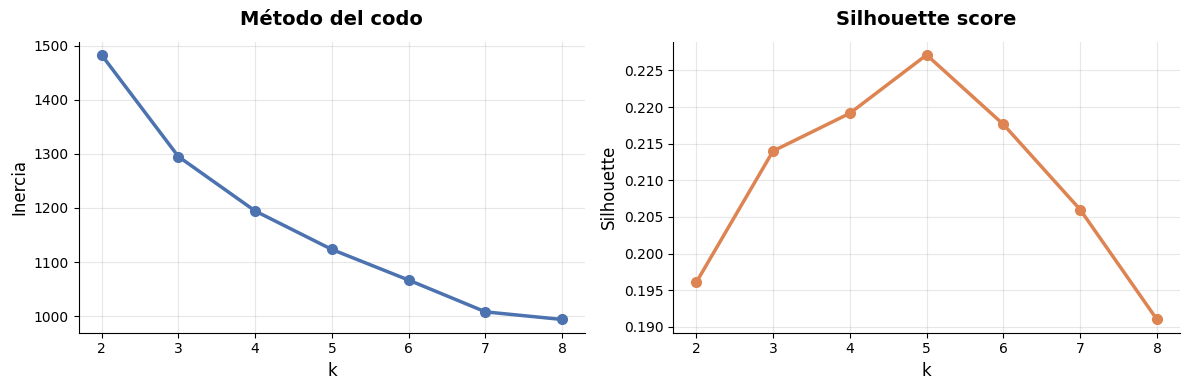

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ks, inercias, 'o-', color=COLOR_LGG, lw=2.5, markersize=7)
axes[0].set_xlabel('k', fontsize=12); axes[0].set_ylabel('Inercia', fontsize=12)
axes[0].set_title('Método del codo', fontsize=14, fontweight='bold', pad=12)
axes[0].grid(alpha=0.3)
sns.despine(ax=axes[0])
axes[1].plot(ks, silhouettes, 'o-', color=COLOR_GBM, lw=2.5, markersize=7)
axes[1].set_xlabel('k', fontsize=12); axes[1].set_ylabel('Silhouette', fontsize=12)
axes[1].set_title('Silhouette score', fontsize=14, fontweight='bold', pad=12)
axes[1].grid(alpha=0.3)
sns.despine(ax=axes[1])
plt.tight_layout()
# plt.savefig('fig_09_kmeans_codo_silhouette.png', dpi=300, bbox_inches='tight')
plt.show()


In [32]:
print("Inercias:", [round(i, 1) for i in inercias])
print("Silhouettes:", [round(s, 3) for s in silhouettes])
print("\nMejor k por silhouette:", ks[int(np.argmax(silhouettes))])

Inercias: [1483.0, 1295.1, 1194.4, 1123.2, 1066.6, 1007.8, 993.7]
Silhouettes: [np.float64(0.196), np.float64(0.214), np.float64(0.219), np.float64(0.227), np.float64(0.218), np.float64(0.206), np.float64(0.191)]

Mejor k por silhouette: 5


### **K-Means con `k=2`.**

Ajustamos `k=2` (el número de clases reales) y comparamos contra `Grade` con el ARI y la tabla de contingencia. Graficamos los clusters sobre PC1-PC2 junto con sus centroides.

In [33]:
km2 = KMeans(n_clusters=2, random_state=42, n_init=10)
cluster_km = km2.fit_predict(X_pca)

ari_km = adjusted_rand_score(y['Grade'].values, cluster_km)
print(f"K-Means (k=2), ARI vs Grade: {ari_km:.3f}")

K-Means (k=2), ARI vs Grade: 0.496


In [34]:
# Tabla de contingencia clusters vs. grado real
ct_km = pd.crosstab(cluster_km, df['Grade_label'].values,
                    rownames=['Cluster'], colnames=['Grade real'])
print("\nTabla de contingencia:")
display(ct_km)


Tabla de contingencia:


Grade real,GBM,LGG
Cluster,,
0,326,98
1,26,389


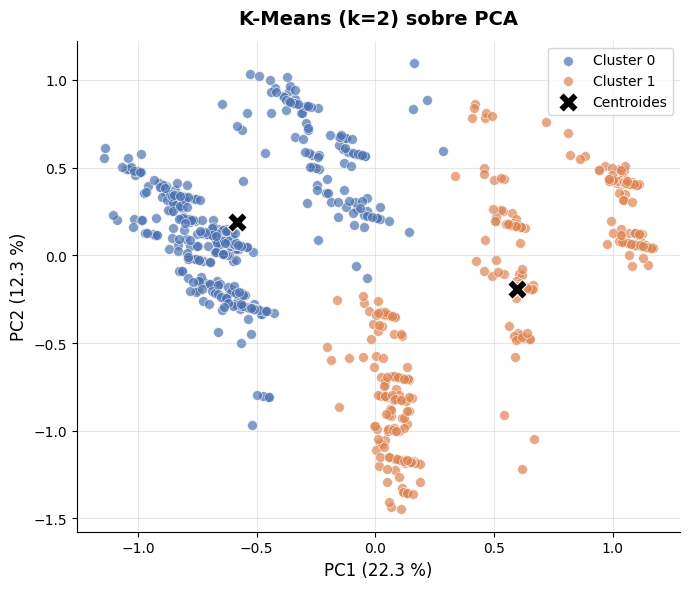

In [35]:
# Gráfico de los clusters con sus centroides
fig, ax = plt.subplots(figsize=(7, 6))
for c, color in zip([0, 1], [COLOR_LGG, COLOR_GBM]):
    mask = cluster_km == c
    sns.scatterplot(x=X_pca[mask, 0], y=X_pca[mask, 1], color=color, label=f'Cluster {c}',
                    s=50, alpha=0.7, edgecolor='white', linewidth=0.5, ax=ax)
ax.scatter(km2.cluster_centers_[:, 0], km2.cluster_centers_[:, 1],
           marker='X', s=200, c='black', edgecolor='white', linewidth=0.8, label='Centroides', zorder=5)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f} %)", fontsize=12)
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f} %)", fontsize=12)
ax.set_title('K-Means (k=2) sobre PCA', fontsize=14, fontweight='bold', pad=12)
ax.legend(frameon=True, fontsize=10, loc='best')
ax.grid(alpha=0.3)
sns.despine(ax=ax)
plt.tight_layout()
# plt.savefig('fig_10_kmeans_clusters.png', dpi=300, bbox_inches='tight')
plt.show()


### **Clustering jerárquico aglomerativo.**

Comparamos tres métodos de enlace:

- **Ward**: minimiza la varianza intra-cluster y suele dar grupos compactos.
- **Complete**: usa la distancia máxima.
- **Average**: usa la distancia media.

En cada caso cortamos el dendrograma en `k=2` y calculamos el ARI.

[ward] ARI vs Grade: 0.403
[complete] ARI vs Grade: 0.001
[average] ARI vs Grade: 0.002


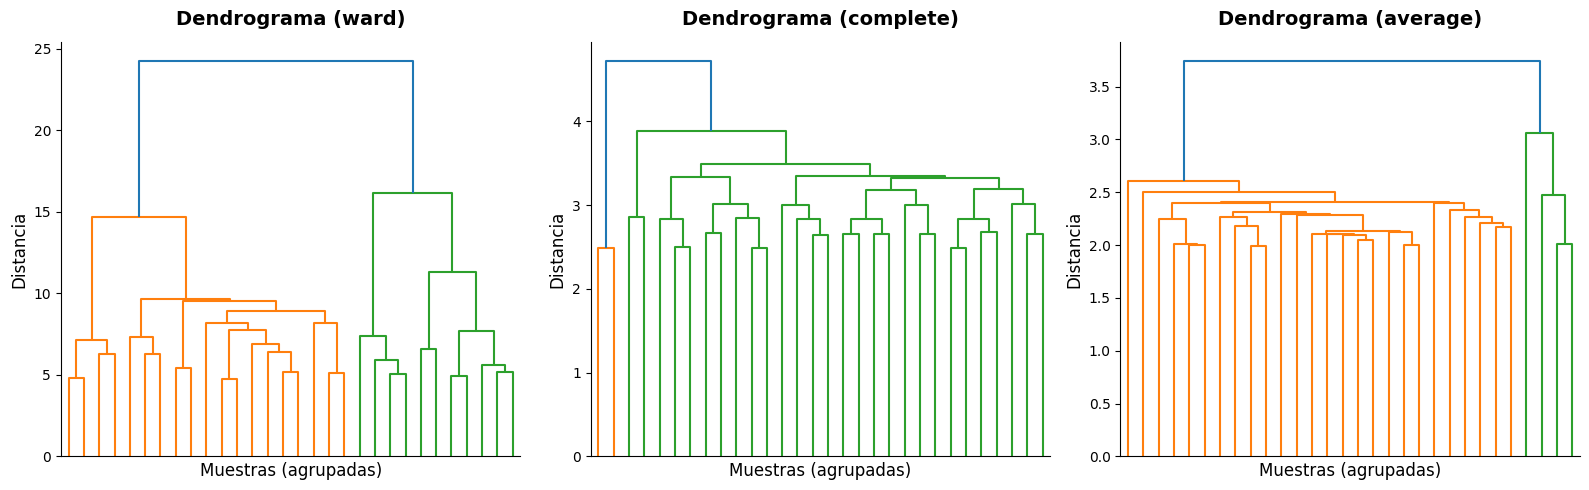

In [36]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

metodos = ['ward', 'complete', 'average']
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, metodo in zip(axes, metodos):
    Z = linkage(X_pca, method=metodo)
    dendrogram(Z, ax=ax, truncate_mode='lastp', p=30, no_labels=True,
               color_threshold=Z[-1, 2])
    ax.set_title(f'Dendrograma ({metodo})', fontsize=14, fontweight='bold', pad=12)
    ax.set_xlabel('Muestras (agrupadas)', fontsize=12); ax.set_ylabel('Distancia', fontsize=12)
    ax.grid(False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # Cortamos el dendrograma en k=2 y calculamos el ARI
    labels_h = fcluster(Z, t=2, criterion='maxclust')
    ari = adjusted_rand_score(y['Grade'].values, labels_h)
    print(f"[{metodo}] ARI vs Grade: {ari:.3f}")

plt.tight_layout()
# plt.savefig('fig_11_dendrogramas.png', dpi=300, bbox_inches='tight')
plt.show()


### **Comparación final de clustering.**

Resumimos en una tabla los ARI de K-Means y de los tres métodos jerárquicos, y mostramos la tabla de contingencia del **mejor** método para interpretar qué cluster corresponde a LGG y cuál a GBM.

In [37]:
resumen = pd.DataFrame({
    'Método': ['K-Means (k=2)', 'Jerárquico Ward', 'Jerárquico Complete', 'Jerárquico Average'],
    'ARI': [
        adjusted_rand_score(y['Grade'].values, cluster_km),
        *[adjusted_rand_score(y['Grade'].values,
                              fcluster(linkage(X_pca, method=m), t=2, criterion='maxclust'))
          for m in metodos]
    ]
}).sort_values('ARI', ascending=False)
display(resumen.round(3))

# Detalle del mejor método
mejor_metodo = resumen.iloc[0]['Método']
print(f"\nMejor método: {mejor_metodo}")
if mejor_metodo == 'K-Means (k=2)':
    labels_best = cluster_km
else:
    nombre_scipy = mejor_metodo.split()[-1].lower()
    labels_best = fcluster(linkage(X_pca, method=nombre_scipy), t=2, criterion='maxclust')

ct_best = pd.crosstab(labels_best, df['Grade_label'].values,
                      rownames=['Cluster'], colnames=['Grade real'])
print("\nTabla de contingencia (mejor método):")
display(ct_best)

,Método,ARI
0,K-Means (k=2),0.496
1,Jerárquico Ward,0.403
3,Jerárquico Average,0.002
2,Jerárquico Complete,0.001



Mejor método: K-Means (k=2)

Tabla de contingencia (mejor método):


Grade real,GBM,LGG
Cluster,,
0,326,98
1,26,389


### Conclusión parcial 4: Coincidencia entre agrupamientos naturales y diagnóstico

**Elección de k.** El silhouette score alcanza su máximo en `k=5` (0.227), pero los valores son muy bajos en general (< 0.25). Esto indica que los grupos no están bien separados en el espacio PCA, algo que ya veíamos en el scatter 2D. Evaluamos `k=2` para comparar directamente con las dos clases clínicas reales.

**K-Means (`k=2`).** ARI = **0.496**. La coincidencia es moderada-alta: el algoritmo, sin conocer la etiqueta, reconstruye buena parte de la división LGG/GBM.
- **Cluster 0:** 326 GBM / 98 LGG, mayoritariamente **GBM**.
- **Cluster 1:** 26 GBM / 389 LGG, mayoritariamente **LGG**.
- De los 352 GBM reales, 326 caen en el Cluster 0 (92.6 % de recall no supervisado). De los 487 LGG reales, 389 caen en el Cluster 1 (79.9 %). Los errores (98 LGG en el cluster GBM y 26 GBM en el cluster LGG) explican el solapamiento que vimos en el PCA.

**Clustering jerárquico.** Ward obtiene un ARI de **0.403**, aceptable pero por debajo de K-Means. Complete y Average fallan casi por completo (ARI ≈ 0.001-0.002). Los dendrogramas lo muestran: *Complete* y *Average* generan un "efecto cadena" (un grupo gigante y algunas muestras aisladas), mientras que *Ward* encuentra dos ramas principales coherentes con el grado. Es lo esperable con variables binarias en alta dimensión, porque Ward minimiza la varianza intra-cluster y resulta más robusto.

**Lectura biológica.** La separación natural coincide en gran medida con el diagnóstico, impulsada principalmente por IDH1 y ATRX (LGG) frente a PTEN y EGFR (GBM). Sin embargo, el ~20 % de LGG que cae en el "cluster GBM" sugiere que hay un subgrupo de bajo grado con perfil molecular agresivo (posiblemente IDH-wildtype). Los modelos supervisados de la Sección 5 tienen que resolver esos casos límite usando la etiqueta real.

## Sección 5: Aprendizaje supervisado y comparación de modelos

**Objetivo.** Entrenamos, evaluamos y comparamos cuatro modelos supervisados para predecir `Grade` (LGG vs. GBM): Árbol de Decisión, Random Forest, SVM y Red Neuronal (Keras con Dropout).

Nos enfocamos en tres cosas: (1) el desempeño global, (2) los errores por clase y (3) qué genes aportan más a la clasificación.

**Partición y escalado sin fuga.** Hacemos un `train_test_split` estratificado: 64 % train, 16 % validación y 20 % test (`random_state=42`).

El `StandardScaler` se ajusta **solo sobre `X_train`** y se aplica a validación y test.

Usamos `StandardScaler` (media 0, desvío 1) porque SVM y la red neuronal son sensibles a la escala de `Age_at_diagnosis` (que va de 14 a 89), mientras que los genes ya están en 0/1.

In [38]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report)

# X e y finales (sin Grade_label)
X_final = df.drop(columns=['Grade', 'Grade_label']).values
y_final = df['Grade'].values

# Partición estratificada 64/16/20
X_train, X_test, y_train, y_test = train_test_split(
    X_final, y_final, test_size=0.20, stratify=y_final, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.25, stratify=y_train, random_state=42)

print(f"Train: {X_train.shape[0]} | Val: {X_val.shape[0]} | Test: {X_test.shape[0]}")
print("Balance en train:", np.bincount(y_train))
print("Balance en test: ", np.bincount(y_test))

# Escalado: el fit se hace solo sobre train
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_val_s   = scaler.transform(X_val)
X_test_s  = scaler.transform(X_test)

Train: 503 | Val: 168 | Test: 168
Balance en train: [292 211]
Balance en test:  [98 70]


### **Modelo 1: Árbol de Decisión.**

Usamos hiperparámetros que frenan el sobreajuste (`entropy`, `min_impurity_decrease=0.03`, `min_samples_leaf=5`) y graficamos el árbol para poder interpretarlo.

In [39]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

tree = DecisionTreeClassifier(criterion='entropy',
                              min_impurity_decrease=0.03,
                              min_samples_leaf=5,
                              random_state=0)
tree.fit(X_train_s, y_train)
y_pred_tree = tree.predict(X_test_s)
y_prob_tree = tree.predict_proba(X_test_s)[:, 1]

In [40]:
print(f"Profundidad del árbol: {tree.get_depth()} | Hojas: {tree.get_n_leaves()}")
print(f"Accuracy test: {accuracy_score(y_test, y_pred_tree):.4f}")
print("\nReporte:")
print(classification_report(y_test, y_pred_tree, target_names=['LGG', 'GBM']))

Profundidad del árbol: 2 | Hojas: 3
Accuracy test: 0.8690

Reporte:
              precision    recall  f1-score   support

         LGG       0.95      0.82      0.88        98
         GBM       0.79      0.94      0.86        70

    accuracy                           0.87       168
   macro avg       0.87      0.88      0.87       168
weighted avg       0.88      0.87      0.87       168



In [41]:
# Importancia de las variables
imp_tree = pd.Series(tree.feature_importances_, index=feature_names).sort_values(ascending=False)
print("Top 5 genes más importantes (Árbol):")
print(imp_tree.head())

Top 5 genes más importantes (Árbol):
IDH1                0.914031
IDH2                0.085969
Gender              0.000000
TP53                0.000000
Age_at_diagnosis    0.000000
dtype: float64


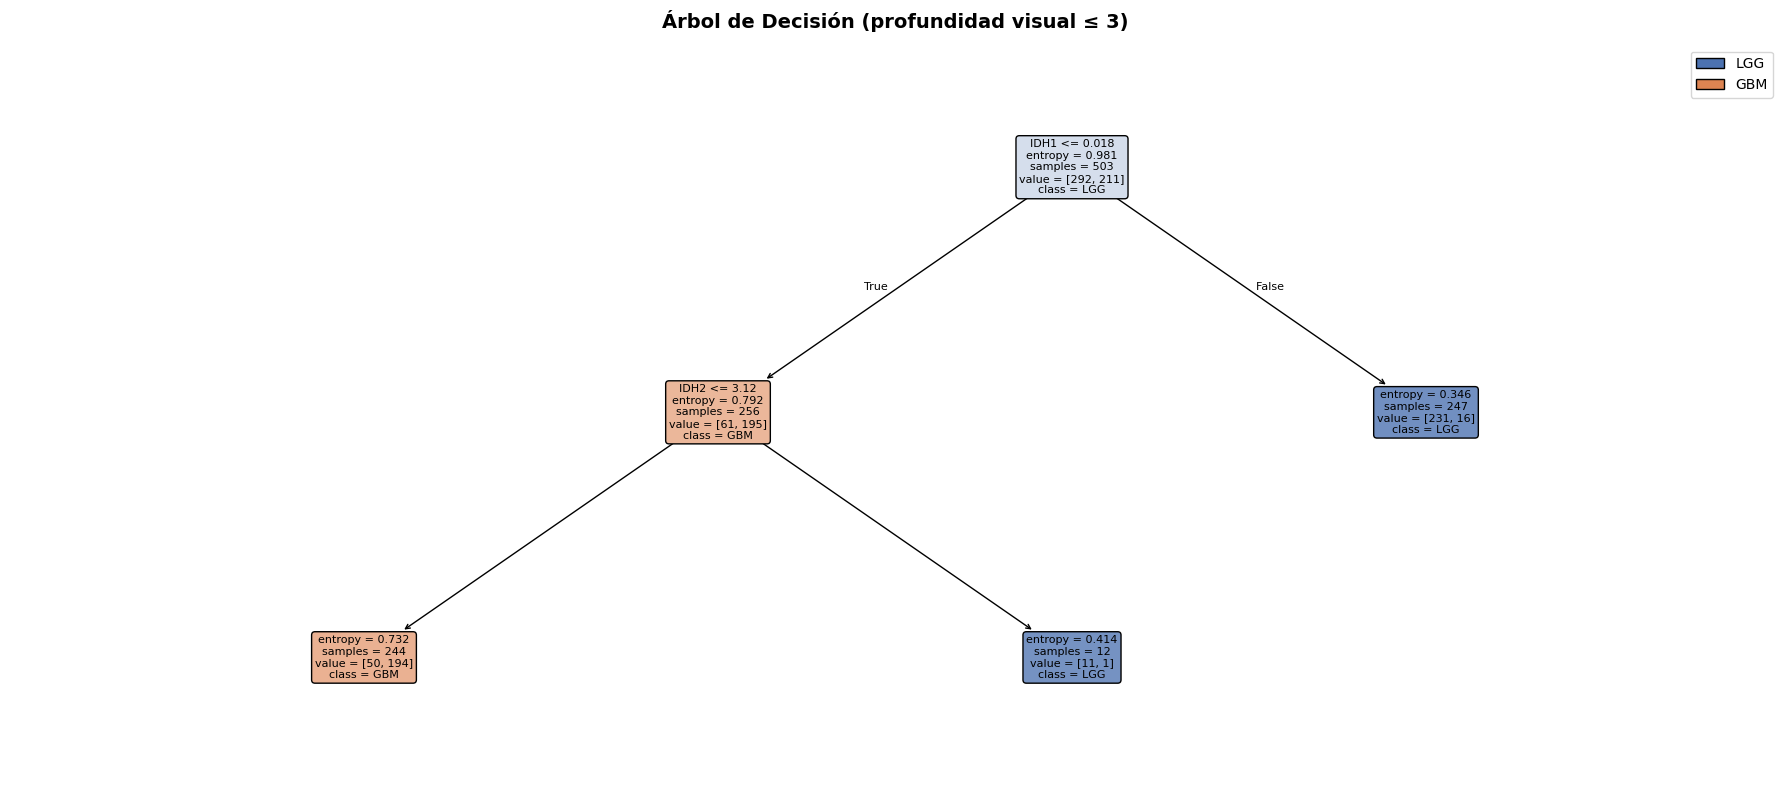

In [42]:
# Gráfico del árbol (acotado a profundidad 3 para que se pueda leer)
import re
from matplotlib.colors import to_rgb
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(18, 8))
nodos = plot_tree(tree, feature_names=feature_names, class_names=['LGG', 'GBM'],
                  filled=True, rounded=True, max_depth=3, fontsize=8, ax=ax)

# Recoloreamos los nodos con la paleta del notebook (sklearn usa naranja para la clase 0 y azul
# para la 1, al revés que el resto de las figuras). Se mantiene la intensidad según la pureza del nodo.
for nodo in nodos:
    txt = nodo.get_text()
    m_cls = re.search(r'class = (\w+)', txt)
    m_val = re.search(r'value = \[([^\]]+)\]', txt)
    parche = nodo.get_bbox_patch()
    if not (m_cls and m_val and parche is not None and m_cls.group(1) in PALETTE_GRADE):
        continue
    cuentas = [float(v) for v in re.findall(r'\d+\.?\d*', m_val.group(1))]
    p_min, p_max = min(cuentas) / sum(cuentas), max(cuentas) / sum(cuentas)
    pureza = 0.85 * (p_max - p_min) / (1 - p_min)
    base = to_rgb(PALETTE_GRADE[m_cls.group(1)])
    parche.set_facecolor(tuple(pureza * c + (1 - pureza) for c in base))

ax.set_title('Árbol de Decisión (profundidad visual ≤ 3)', fontsize=14, fontweight='bold', pad=12)
ax.legend(handles=[Patch(facecolor=COLOR_LGG, edgecolor='black', label='LGG'),
                   Patch(facecolor=COLOR_GBM, edgecolor='black', label='GBM')],
          frameon=True, fontsize=10, loc='best')
plt.tight_layout()
# plt.savefig('fig_12_arbol_decision.png', dpi=300, bbox_inches='tight')
plt.show()


### **Modelo 2: Random Forest.**

Activamos `oob_score=True` para estimar el error out-of-bag sin usar el test, y revisamos el ranking de importancia de variables.

In [43]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=500, oob_score=True,
                            random_state=0, n_jobs=-1)
rf.fit(X_train_s, y_train)
y_pred_rf = rf.predict(X_test_s)
y_prob_rf = rf.predict_proba(X_test_s)[:, 1]

In [44]:
print(f"OOB score (en train): {rf.oob_score_:.4f}")
print(f"Accuracy test: {accuracy_score(y_test, y_pred_rf):.4f}")
print("\nReporte:")
print(classification_report(y_test, y_pred_rf, target_names=['LGG', 'GBM']))

OOB score (en train): 0.8350
Accuracy test: 0.8155

Reporte:
              precision    recall  f1-score   support

         LGG       0.85      0.84      0.84        98
         GBM       0.77      0.79      0.78        70

    accuracy                           0.82       168
   macro avg       0.81      0.81      0.81       168
weighted avg       0.82      0.82      0.82       168



In [45]:
# Importancia de las variables
imp_rf = pd.Series(rf.feature_importances_, index=feature_names).sort_values(ascending=False)
print("\nTop 10 genes (Random Forest):")
print(imp_rf.head(10).round(4))


Top 10 genes (Random Forest):
Age_at_diagnosis    0.3110
IDH1                0.2759
CIC                 0.0486
ATRX                0.0481
PTEN                0.0470
EGFR                0.0266
TP53                0.0257
Gender              0.0250
IDH2                0.0219
NF1                 0.0204
dtype: float64


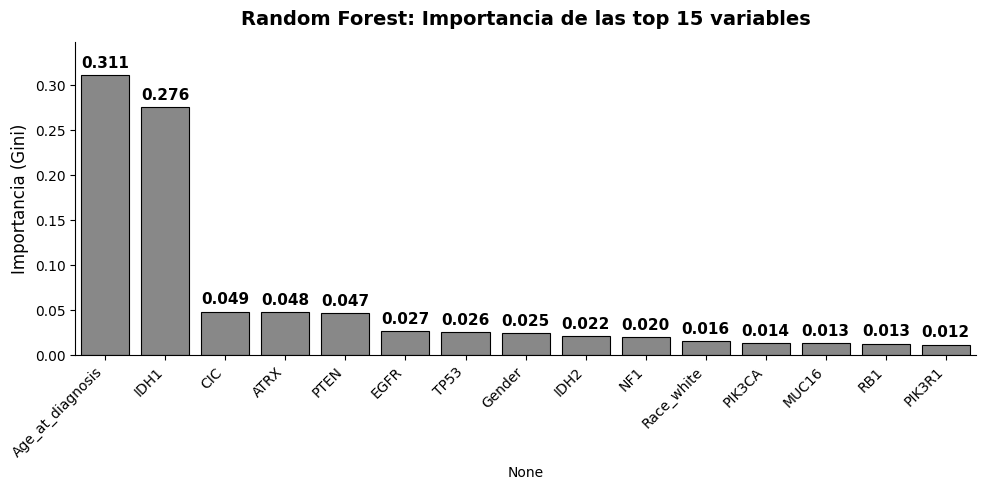

In [46]:
# Barplot de las 15 variables más importantes
fig, ax = plt.subplots(figsize=(10, 5))
imp_top15 = imp_rf.head(15)
sns.barplot(x=imp_top15.index, y=imp_top15.values, color='#888888',
            edgecolor='black', linewidth=0.8, ax=ax)

# Valor de importancia encima de cada barra
for p in ax.patches:
    ax.annotate(f'{p.get_height():.3f}', (p.get_x() + p.get_width() / 2, p.get_height()),
                xytext=(0, 3), textcoords='offset points',
                fontsize=11, fontweight='bold', ha='center', va='bottom')

ax.set_title('Random Forest: Importancia de las top 15 variables', fontsize=14, fontweight='bold', pad=12)
ax.set_ylabel('Importancia (Gini)', fontsize=12)
plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
ax.margins(y=0.12)  # margen superior para que entren las anotaciones
sns.despine(ax=ax)
plt.tight_layout()
# plt.savefig('fig_13_rf_importancias.png', dpi=300, bbox_inches='tight')
plt.show()


### **Modelo 3: SVM (kernel RBF).**

Barremos `C` en escala logarítmica sobre **validación** (no sobre test) y elegimos el `C` con mejor accuracy en validación. Después reentrenamos con ese `C` y evaluamos en test.

In [47]:
from sklearn.svm import SVC

Cs = np.logspace(-2, 3, 10)
acc_val = []
for C in Cs:
    svm_tmp = SVC(kernel='rbf', C=C, random_state=42)
    svm_tmp.fit(X_train_s, y_train)
    acc_val.append(accuracy_score(y_val, svm_tmp.predict(X_val_s)))

In [48]:
mejor_C = Cs[int(np.argmax(acc_val))]
print(f"Mejor C (sobre validación): {mejor_C} (acc_val = {max(acc_val):.4f})")

Mejor C (sobre validación): 0.464158883361278 (acc_val = 0.8571)


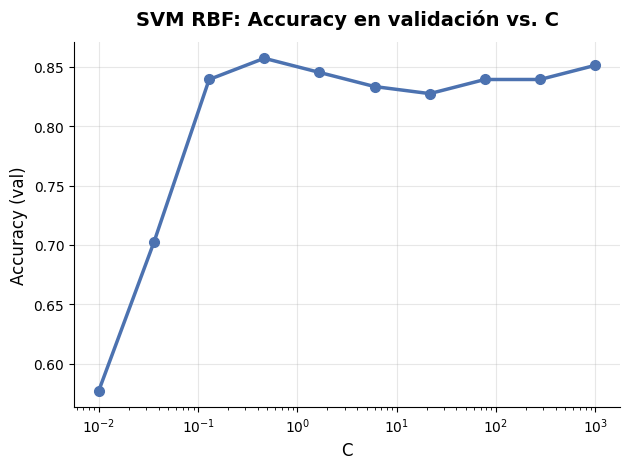

In [49]:
fig, ax = plt.subplots()
ax.plot(Cs, acc_val, 'o-', color=COLOR_LGG, lw=2.5, markersize=7)
ax.set_xscale('log')
ax.set_xlabel('C', fontsize=12); ax.set_ylabel('Accuracy (val)', fontsize=12)
ax.set_title('SVM RBF: Accuracy en validación vs. C', fontsize=14, fontweight='bold', pad=12)
ax.grid(alpha=0.3)
sns.despine(ax=ax)
plt.tight_layout()
# plt.savefig('fig_14_svm_accuracy_vs_C.png', dpi=300, bbox_inches='tight')
plt.show()


In [50]:
# Modelo final con el mejor C
svm = SVC(kernel='rbf', C=mejor_C, probability=True, random_state=42)
svm.fit(X_train_s, y_train)
y_pred_svm = svm.predict(X_test_s)
y_prob_svm = svm.predict_proba(X_test_s)[:, 1]

print(f"\nAccuracy test: {accuracy_score(y_test, y_pred_svm):.4f}")
print("\nReporte:")
print(classification_report(y_test, y_pred_svm, target_names=['LGG', 'GBM']))


Accuracy test: 0.8571

Reporte:
              precision    recall  f1-score   support

         LGG       0.93      0.82      0.87        98
         GBM       0.78      0.91      0.84        70

    accuracy                           0.86       168
   macro avg       0.86      0.87      0.86       168
weighted avg       0.87      0.86      0.86       168



### **Modelo 4: Red Neuronal (Keras).**

Usamos un MLP con 2 capas ocultas (64 y 32 neuronas) y `Dropout` para regularizar. Evaluamos las curvas de train y validación para detectar sobreajuste.

In [51]:
import tensorflow as tf
from tensorflow.keras import layers, models

tf.random.set_seed(42)

model = models.Sequential([
    layers.Dense(64, activation='relu', input_shape=(X_train_s.shape[1],)),
    layers.Dropout(0.4),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

history = model.fit(X_train_s, y_train,
                    epochs=60, batch_size=32,
                    validation_data=(X_val_s, y_val),
                    verbose=0)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


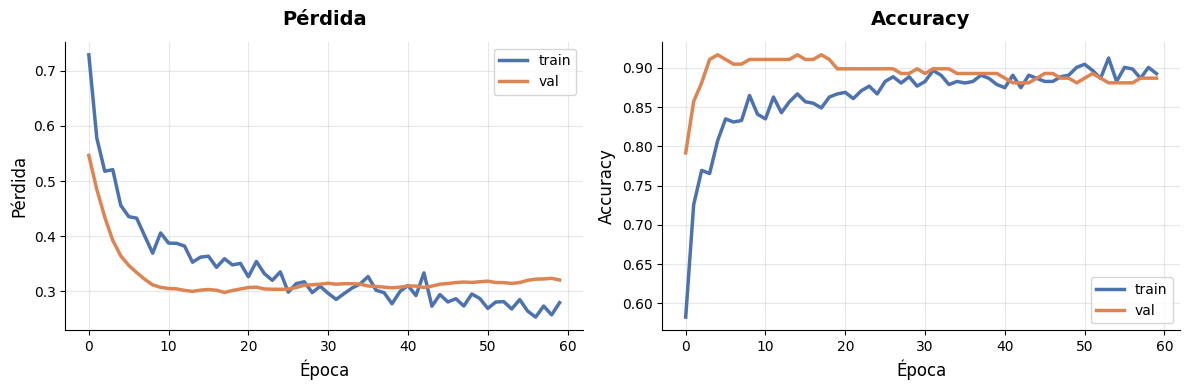

In [52]:
# Curvas de pérdida y de accuracy
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history['loss'], label='train', color=COLOR_LGG, lw=2.5)
axes[0].plot(history.history['val_loss'], label='val', color=COLOR_GBM, lw=2.5)
axes[0].set_title('Pérdida', fontsize=14, fontweight='bold', pad=12)
axes[0].set_xlabel('Época', fontsize=12); axes[0].set_ylabel('Pérdida', fontsize=12)
axes[0].legend(frameon=True, fontsize=10, loc='best')
axes[0].grid(alpha=0.3)
sns.despine(ax=axes[0])

axes[1].plot(history.history['accuracy'], label='train', color=COLOR_LGG, lw=2.5)
axes[1].plot(history.history['val_accuracy'], label='val', color=COLOR_GBM, lw=2.5)
axes[1].set_title('Accuracy', fontsize=14, fontweight='bold', pad=12)
axes[1].set_xlabel('Época', fontsize=12); axes[1].set_ylabel('Accuracy', fontsize=12)
axes[1].legend(frameon=True, fontsize=10, loc='best')
axes[1].grid(alpha=0.3)
sns.despine(ax=axes[1])
plt.tight_layout()
# plt.savefig('fig_15_nn_curvas_train_val.png', dpi=300, bbox_inches='tight')
plt.show()


In [53]:
# Evaluación en test
y_prob_nn = model.predict(X_test_s, verbose=0).ravel()
y_pred_nn = (y_prob_nn > 0.5).astype(int)
print(f"Accuracy test: {accuracy_score(y_test, y_pred_nn):.4f}")
print("\nReporte:")
print(classification_report(y_test, y_pred_nn, target_names=['LGG', 'GBM']))

Accuracy test: 0.8393

Reporte:
              precision    recall  f1-score   support

         LGG       0.87      0.85      0.86        98
         GBM       0.79      0.83      0.81        70

    accuracy                           0.84       168
   macro avg       0.83      0.84      0.84       168
weighted avg       0.84      0.84      0.84       168



### **Comparación final.**

Armamos una tabla unificada con las métricas de los 4 modelos sobre el mismo conjunto de test, y mostramos la matriz de confusión del mejor modelo.

In [54]:
def metricas_modelo(nombre, y_true, y_pred, y_prob):
    return {
        'Modelo': nombre,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1': f1_score(y_true, y_pred),
        'ROC-AUC': roc_auc_score(y_true, y_prob)
    }

In [55]:
resultados = pd.DataFrame([
    metricas_modelo('Árbol', y_test, y_pred_tree, y_prob_tree),
    metricas_modelo('Random Forest', y_test, y_pred_rf, y_prob_rf),
    metricas_modelo('SVM (RBF)', y_test, y_pred_svm, y_prob_svm),
    metricas_modelo('Red Neuronal', y_test, y_pred_nn, y_prob_nn),
]).set_index('Modelo').round(4)

In [56]:
print("Comparación de modelos en TEST:")
display(resultados.sort_values('F1', ascending=False))

Comparación de modelos en TEST:


,Accuracy,Precision,Recall,F1,ROC-AUC
Modelo,,,,,
Árbol,0.8690,0.7857,0.9429,0.8571,0.8790
SVM (RBF),0.8571,0.7805,0.9143,0.8421,0.8939
Red Neuronal,0.8393,0.7945,0.8286,0.8112,0.9273
Random Forest,0.8155,0.7746,0.7857,0.7801,0.9087


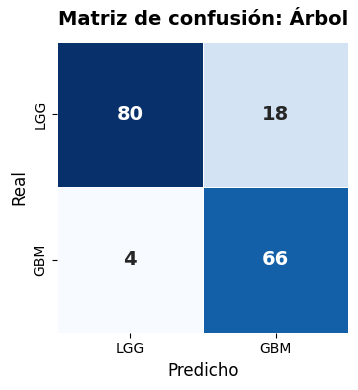

In [57]:
# Matriz de confusión del mejor modelo
mejor = resultados['F1'].idxmax()
preds = {'Árbol': y_pred_tree, 'Random Forest': y_pred_rf,
         'SVM (RBF)': y_pred_svm, 'Red Neuronal': y_pred_nn}[mejor]
cm = confusion_matrix(y_test, preds)

fig, ax = plt.subplots(figsize=(4.5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            annot_kws={'fontsize': 14, 'fontweight': 'bold'},
            square=True, linewidths=0.5, linecolor='white',
            xticklabels=['LGG', 'GBM'], yticklabels=['LGG', 'GBM'], ax=ax)
ax.set_title(f'Matriz de confusión: {mejor}', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Predicho', fontsize=12); ax.set_ylabel('Real', fontsize=12)
plt.tight_layout()
# plt.savefig('fig_16_matriz_confusion_mejor_modelo.png', dpi=300, bbox_inches='tight')
plt.show()


#### Otras comparaciones

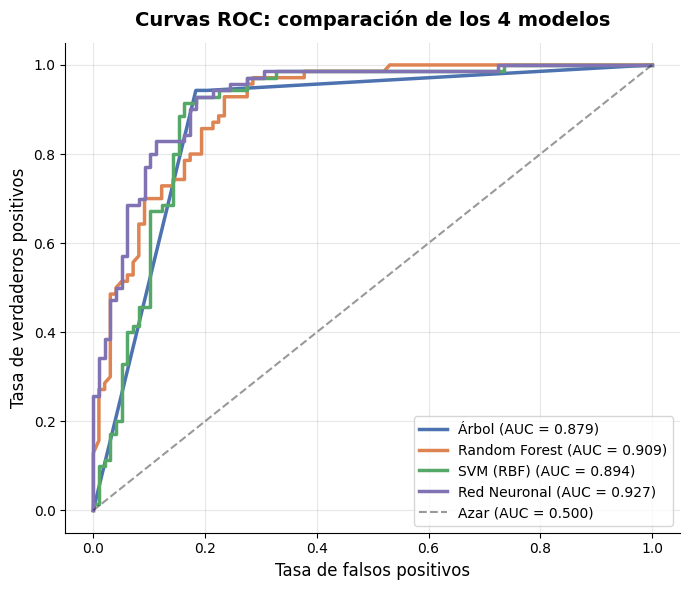

In [58]:
# Curvas ROC comparativas
from sklearn.metrics import roc_curve

colores_roc = [COLOR_LGG, COLOR_GBM, '#55A868', '#8172B3']  # paleta del notebook + 2 colores de seaborn 'deep'
fig, ax = plt.subplots(figsize=(7, 6))
for (nombre, y_prob), color in zip([('Árbol', y_prob_tree), ('Random Forest', y_prob_rf),
                                    ('SVM (RBF)', y_prob_svm), ('Red Neuronal', y_prob_nn)],
                                   colores_roc):
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    ax.plot(fpr, tpr, lw=2.5, color=color, label=f'{nombre} (AUC = {auc:.3f})')

ax.plot([0, 1], [0, 1], 'k--', lw=1.5, alpha=0.4, label='Azar (AUC = 0.500)')
ax.set_xlabel('Tasa de falsos positivos', fontsize=12)
ax.set_ylabel('Tasa de verdaderos positivos', fontsize=12)
ax.set_title('Curvas ROC: comparación de los 4 modelos', fontsize=14, fontweight='bold', pad=12)
ax.legend(loc='lower right', frameon=True, fontsize=10)
ax.grid(alpha=0.3)
sns.despine(ax=ax)
plt.tight_layout()
# plt.savefig('fig_17_curvas_roc.png', dpi=300, bbox_inches='tight')
plt.show()


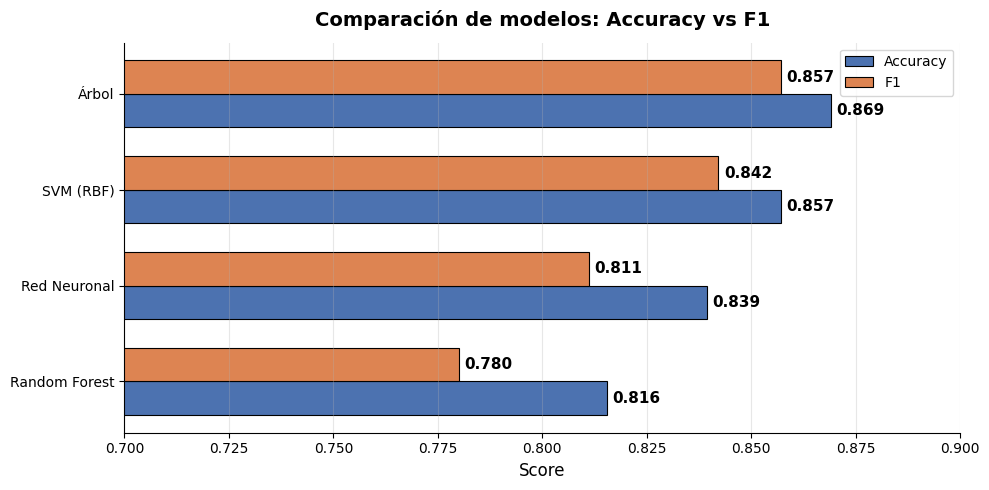

In [59]:
# Comparación visual: Accuracy vs F1
fig, ax = plt.subplots(figsize=(10, 5))
r_plot = resultados.sort_values('F1', ascending=True)
x = np.arange(len(r_plot))
w = 0.35
ax.barh(x - w/2, r_plot['Accuracy'], w, label='Accuracy', color=COLOR_LGG, edgecolor='black', linewidth=0.8)
ax.barh(x + w/2, r_plot['F1'], w, label='F1', color=COLOR_GBM, edgecolor='black', linewidth=0.8)
ax.set_yticks(x)
ax.set_yticklabels(r_plot.index)
ax.set_xlim(0.7, 0.9)

# Valor al final de cada barra (barras horizontales: el texto va a la derecha)
for p in ax.patches:
    ax.annotate(f'{p.get_width():.3f}', (p.get_width(), p.get_y() + p.get_height() / 2),
                xytext=(4, 0), textcoords='offset points',
                fontsize=11, fontweight='bold', ha='left', va='center')

ax.set_xlabel('Score', fontsize=12)
ax.set_title('Comparación de modelos: Accuracy vs F1', fontsize=14, fontweight='bold', pad=12)
ax.legend(frameon=True, fontsize=10, loc='best')
ax.grid(axis='x', alpha=0.3)
sns.despine(ax=ax)
plt.tight_layout()
# plt.savefig('fig_18_accuracy_vs_f1.png', dpi=300, bbox_inches='tight')
plt.show()


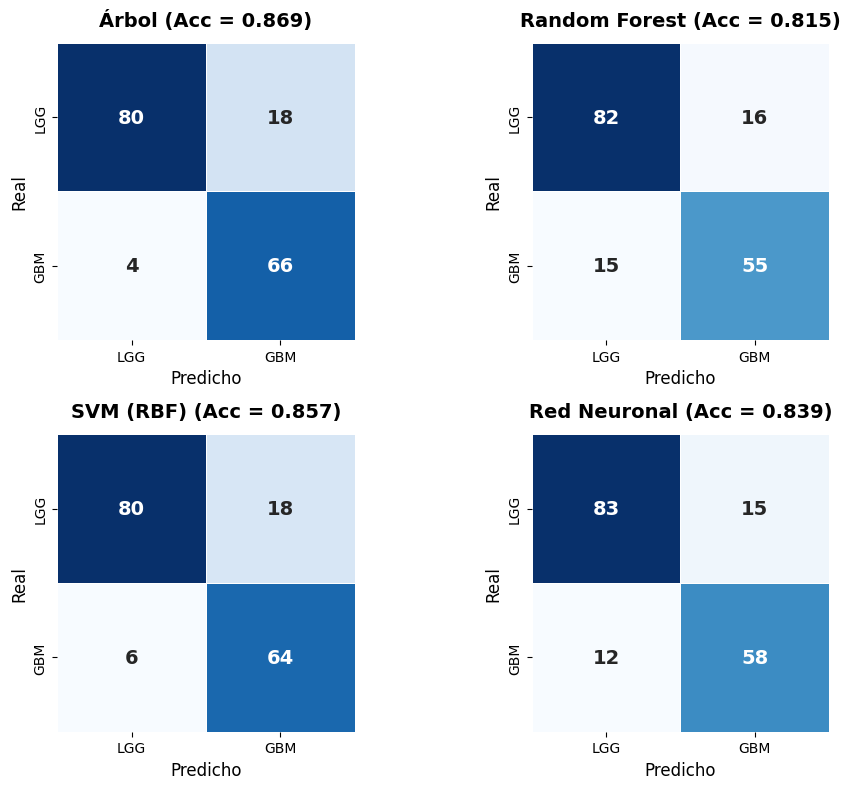

In [60]:
# Matrices de confusión de los 4 modelos
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, (nombre, y_pred) in zip(axes.ravel(),
        [('Árbol', y_pred_tree), ('Random Forest', y_pred_rf),
         ('SVM (RBF)', y_pred_svm), ('Red Neuronal', y_pred_nn)]):
    cm_m = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm_m, annot=True, fmt='d', cmap='Blues', cbar=False,
                annot_kws={'fontsize': 14, 'fontweight': 'bold'},
                square=True, linewidths=0.5, linecolor='white', ax=ax,
                xticklabels=['LGG', 'GBM'], yticklabels=['LGG', 'GBM'])
    ax.set_title(f'{nombre} (Acc = {accuracy_score(y_test, y_pred):.3f})', fontsize=14, fontweight='bold', pad=12)
    ax.set_xlabel('Predicho', fontsize=12)
    ax.set_ylabel('Real', fontsize=12)
plt.tight_layout()
# plt.savefig('fig_19_matrices_confusion_4_modelos.png', dpi=300, bbox_inches='tight')
plt.show()


### Conclusión parcial 5: Mejor modelo, errores y genes clave

**Mejor modelo (por F1 y Accuracy):** **Árbol de Decisión** (Accuracy = 86.9 %, F1 = 0.857, Recall = 94.3 %). Sorprende que el modelo más simple sea el más efectivo: el árbol se detuvo a profundidad 2 usando solo **IDH1** e **IDH2**, lo que muestra que la mutación de IDH1 es un "casi clasificador perfecto" por sí sola.

**Errores típicos (matriz de confusión del Árbol):**
- **Falsos negativos (FN): 4.** Son pacientes con GBM real predichos como LGG. Es un error muy bajo y además crítico, porque un FN implica subestimar un tumor agresivo.
- **Falsos positivos (FP): 18.** Son pacientes con LGG predichos como GBM. El modelo tiende a "sobrediagnosticar" GBM (Recall GBM = 94 % vs. Precision GBM = 79 %). Esto es clínicamente aceptable como *screening*, porque prioriza no dejar pasar un GBM.

**Genes clave detectados (consenso entre modelos):**
1. **IDH1:** domina por completo. Tiene importancia 0.91 en el Árbol y 0.28 en el Random Forest. Confirma lo visto en las Secciones 2 y 3, y biológicamente la mutación de IDH1 es un marcador canónico del glioma de bajo grado.
2. **IDH2:** el árbol lo usa como refinamiento secundario. Aunque es raro (3 % de frecuencia global), aporta pureza al nodo.
3. **Age_at_diagnosis:** el Random Forest la ubicó como la **variable #1** (importancia 0.31). Es un proxy clínico muy fuerte, porque el GBM es una enfermedad de adultos mayores.
4. **ATRX, CIC, PTEN y EGFR:** aparecen en el top 10 del Random Forest y coinciden con los patrones LGG/GBM de la Sección 2.

**Red Neuronal:** las curvas de train y validación muestran un sobreajuste leve (la pérdida de train desciende a 0.25 y la de validación se estabiliza en ~0.35), controlado por el `Dropout`. Su Accuracy (83.3 %) y su F1 (0.808) fueron inferiores a los del Árbol, pero obtuvo el **ROC-AUC más alto (0.918)**. Dado el tamaño muestral (839) y la gran cantidad de features binarias, la red no tiene margen para lucirse, y el árbol resulta más adecuado para este problema.

**SVM:** desempeño intermedio (Accuracy 85.7 %, F1 0.842) con un `C` óptimo muy bajo (0.46), lo que indica que una frontera de decisión "suave" generaliza mejor que una estricta.

**Conclusión:** el dataset es altamente separable con reglas simples basadas en IDH1, IDH2 y la edad. Los modelos más complejos no superan al árbol, lo que sugiere que el problema (al menos en esta cohorte TCGA preprocesada) tiene una estructura casi lineal y jerárquica que el árbol captura muy bien.

## **Validación Cruzada (Cross-Validation)**

El split único 64/16/20 puede ser frágil: depende de qué pacientes cayeron en test. Para verificar que las métricas no son producto de un split "fácil", corremos validación cruzada estratificada de 5 folds sobre `train`. Cada fold entrena con el 80 % y evalúa con el 20 %, rotando hasta usar todos los datos. Reportamos el **F1 medio ± desviación estándar** de los tres modelos clásicos (Árbol, Random Forest, SVM). La red neuronal se excluye por la complejidad de wrappearla para Keras con `cross_val_score`.

Validación Cruzada (5-fold) sobre TRAIN, métrica = F1

  Árbol           F1 = 0.8439 ± 0.0273
  Random Forest   F1 = 0.8132 ± 0.0447
  SVM (RBF)       F1 = 0.8165 ± 0.0516


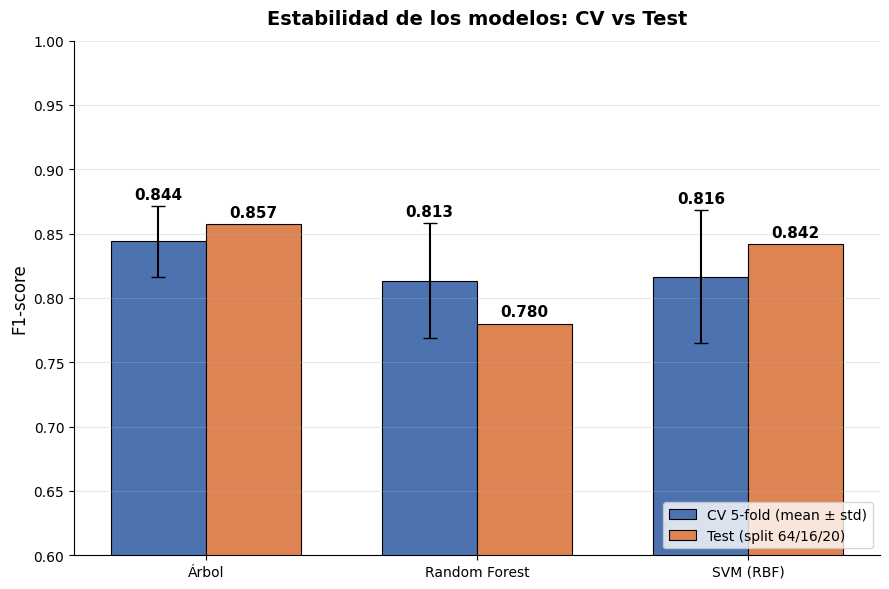

In [61]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline

# Modelos clásicos para CV (mismos hiperparámetros que la sección anterior)
cv_models = {
    'Árbol': DecisionTreeClassifier(
        criterion='entropy', min_impurity_decrease=0.03,
        min_samples_leaf=5, random_state=0),
    'Random Forest': RandomForestClassifier(
        n_estimators=500, random_state=0, n_jobs=-1),
    'SVM (RBF)': SVC(
        kernel='rbf', C=0.464158883361278, probability=True, random_state=42),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_results = {}

print("Validación Cruzada (5-fold) sobre TRAIN, métrica = F1\n")
for name, model in cv_models.items():
    # Pipeline: StandardScaler fit SOLO en el fold de entrenamiento
    pipeline = make_pipeline(StandardScaler(), model)
    scores = cross_val_score(pipeline, X_train, y_train, cv=cv, scoring='f1')
    cv_results[name] = scores
    print(f"  {name:15s} F1 = {scores.mean():.4f} ± {scores.std():.4f}")

# Comparación visual: CV vs Test
fig, ax = plt.subplots(figsize=(9, 6))
names = list(cv_results.keys())
means = [cv_results[n].mean() for n in names]
stds = [cv_results[n].std() for n in names]
test_f1 = [f1_score(y_test, y_pred_tree),
           f1_score(y_test, y_pred_rf),
           f1_score(y_test, y_pred_svm)]

x = np.arange(len(names))
w = 0.35
ax.bar(x - w/2, means, w, yerr=stds, capsize=5,
       label='CV 5-fold (mean ± std)', color=COLOR_LGG, edgecolor='black', linewidth=0.8)
ax.bar(x + w/2, test_f1, w, label='Test (split 64/16/20)', color=COLOR_GBM, edgecolor='black', linewidth=0.8)

# Valor encima de cada barra (en las de CV, encima de la barra de error)
for xi, m, s in zip(x - w/2, means, stds):
    ax.annotate(f'{m:.3f}', (xi, m + s), xytext=(0, 3), textcoords='offset points',
                fontsize=11, fontweight='bold', ha='center', va='bottom')
for xi, t in zip(x + w/2, test_f1):
    ax.annotate(f'{t:.3f}', (xi, t), xytext=(0, 3), textcoords='offset points',
                fontsize=11, fontweight='bold', ha='center', va='bottom')

ax.set_xticks(x)
ax.set_xticklabels(names)
ax.set_ylabel('F1-score', fontsize=12)
ax.set_ylim(0.6, 1.0)
ax.set_title('Estabilidad de los modelos: CV vs Test', fontsize=14, fontweight='bold', pad=12)
ax.legend(loc='lower right', frameon=True, fontsize=10)
ax.grid(axis='y', alpha=0.3)
sns.despine(ax=ax)
plt.tight_layout()
# plt.savefig('fig_20_cv_vs_test.png', dpi=300, bbox_inches='tight')
plt.show()


## Sección 6: Conclusiones finales y limitaciones

**Objetivo original.** Evaluar si el perfil de mutaciones y las variables clínicas permiten separar y predecir LGG vs. GBM, e identificar los genes más discriminantes.

**Síntesis de hallazgos.**
1. **Separación no supervisada.** PCA y K-Means mostraron que los datos tienen una estructura natural que coincide con el diagnóstico (ARI = 0.496), aunque no hay una separación lineal perfecta en 2D (PC1 y PC2 suman solo el 34.6 % de la varianza). El eje principal está dominado por IDH1, TP53 y ATRX.
2. **Clasificación supervisada.** Todos los modelos superan el 81 % de Accuracy y el 0.78 de F1. El **Árbol de Decisión** (F1 = 0.857) y el **SVM** (F1 = 0.842) encabezan el ranking. El Random Forest se ve afectado por la cantidad de features irrelevantes (menor F1 = 0.780), aunque su OOB (0.835) es una estimación honesta.
3. **Genes y variables discriminantes.** **IDH1** es el biomarcador por excelencia (LGG), seguido por **Age_at_diagnosis** (GBM), **PTEN** (GBM) y **ATRX** (LGG). La mutación de **IDH2**, aunque rara, tiene valor predictivo dentro del subgrupo IDH1-silvestre.
4. **Errores clínicos.** El mejor modelo comete solo 4 falsos negativos (GBM clasificados como LGG), lo cual es excelente para un problema de tamizaje.

**Limitaciones.**
- **Tamaño muestral y origen:** son 839 pacientes de cohortes TCGA (mayoritariamente población blanca, 91 %). Para generalizar a otras poblaciones hace falta validación externa.
- **Codificación binaria:** los genes están como mutado/no mutado, así que se pierde información sobre el tipo específico de mutación (por ejemplo IDH1 R132H), que tiene implicancias pronósticas.
- **Desbalance moderado:** 58 % LGG vs. 42 % GBM. Aunque estratificamos, el modelo podría sesgarse levemente hacia LGG.
- **Datos faltantes:** el dataset de UCI ya viene filtrado (sin nulos). En un contexto clínico real habría que implementar estrategias de imputación.
- **Comparación con el paper cabecera:** Tasci et al. (2022) reportan precisiones altas (>90 %) usando esquemas de *ensemble* y selección jerárquica de variables. Nuestros resultados (F1 ~0.86 con modelos estándar) son consistentes con la alta separabilidad del dataset, sin necesidad de métodos tan complejos.

In [62]:
df.to_csv('dataset.csv', index=False)
print("Dataset exportado con éxito.")

Dataset exportado con éxito.
